# EDA, ablasi ML, dan error analysis lengkap klasifikasi daun

Notebook menyediakan dua mode. Pilih pengaturan pada cell setup sebelum menjalankan dari kernel baru.

| Tujuan | USE_GITHUB_ARTIFACTS | REPRODUCE_GITHUB_RUN |
|---|---|---|
| Membaca hasil lama, tanpa training | True | False |
| Melatih ulang untuk mereproduksi run lama | False | True |

**Default tetap membaca artefak.** Untuk benar-benar training ulang, ubah menjadi `USE_GITHUB_ARTIFACTS=False` dan `REPRODUCE_GITHUB_RUN=True`, kemudian Restart Kernel dan Run All. Pertahankan `RUN_NEW_DIAGNOSTIC_MODELS=False` untuk fokus pada benchmark.

Dalam mode reproduksi, GitHub hanya dipakai sebagai referensi data, split, konfigurasi dan pembanding. SVM/RF benar-benar di-fit ulang, kandidat profil serta parameter dipilih ulang melalui inner CV, dan prediksi outer-test dibuat ulang. Hasil tidak diganti dengan prediksi lama.

Yang diperiksa/dikunci: seed 42, foto beserta urutan dan hash piksel, split outer 5 fold, seed inner 43?47 dengan 3 fold, augmentasi beserta seed tiap foto, MAX_SIDE 640, kandidat fitur/grid model, RF 200 pohon, satu thread OpenCV/BLAS, Python 3.10.20, scikit-learn 1.7.2 dan OpenCV 5.0.0. NumPy/SciPy/Pillow dicatat untuk run baru, tetapi versinya tidak terekam pada run historis. Kesamaan lintas environment/hardware tidak dijamin hanya dengan seed.

## Pemeriksaan hasil training ulang

- `reproduction_comparison.json`: jumlah prediksi yang berbeda, kecocokan skor, profil dan parameter
- `reproduction_prediction_differences.csv`: foto/pipeline yang prediksinya berubah
- `reproduction_metrics_comparison.csv`: skor baru, skor GitHub dan selisih per fold/pipeline

Skor dibandingkan dengan toleransi numerik 1e-12. Prediksi dibandingkan persis. Waktu proses dan bobot model tidak dibandingkan, karena waktu dapat berubah dan bobot model lama tidak tersimpan. Berkas profil/parameter lama tidak dipakai untuk memaksa hasil tuning.

Output reproduksi disimpan di `ablasi ML awal/reproduksi_github_f2473327_lengkap`. Analisis tambahan memakai hasil training baru pada mode reproduksi, dan memakai artefak GitHub pada mode baca. Cache dan cadangan tetap di drive E dalam `.cache`. Bagian 13?15 berisi eksperimen diagnostik terpisah yang nonaktif secara default.

Acak ulang secara konsisten dijelaskan pada [dokumentasi scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html#controlling-randomness).

## Salinan publikasi GitHub

Folder aktif pada repositori adalah ablasi ML awal. Folder Notebook di dalam snapshot historis dipertahankan agar hash dan sumber commit lama tetap valid.

Output eksekusi dipertahankan dari run lokal. Path absolut lama adalah provenance, bukan lokasi yang wajib dibuat di komputer lain. Cache/cadangan lokal tidak dipublikasikan.


In [1]:
# Semua file sementara/cadangan notebook berada di drive proyek (E:).
from pathlib import Path
import os, sys, tempfile
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'Dataset/metadata.csv').exists()), None)
assert ROOT is not None, 'Jalankan dari direktori proyek atau Notebook.'
PROJECT_CACHE = ROOT/'.cache'
cache_locations = {'TEMP':PROJECT_CACHE/'tmp', 'TMP':PROJECT_CACHE/'tmp',
                   'MPLCONFIGDIR':PROJECT_CACHE/'matplotlib',
                   'JOBLIB_TEMP_FOLDER':PROJECT_CACHE/'joblib',
                   'PYTHONPYCACHEPREFIX':PROJECT_CACHE/'pycache'}
for variable, directory in cache_locations.items():
    directory.mkdir(parents=True, exist_ok=True)
    os.environ[variable] = str(directory)
tempfile.tempdir = str(PROJECT_CACHE/'tmp')
sys.pycache_prefix = str(PROJECT_CACHE/'pycache')

from pathlib import Path
import os, sys, json, time, hashlib, platform, warnings
from functools import lru_cache
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import cv2
import sklearn
from sklearn.cluster import MiniBatchKMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits
from IPython.display import display

SMOKE_TEST = False
SEED = 42
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'Dataset/metadata.csv').exists()), None)
assert ROOT is not None, 'Jalankan dari direktori proyek atau Notebook.'
# Sumber hasil dikunci ke snapshot GitHub yang sudah dipulihkan dan diverifikasi.
USE_GITHUB_ARTIFACTS = False
REPRODUCE_GITHUB_RUN = True
RUN_NEW_DIAGNOSTIC_MODELS = True
GITHUB_COMMIT = 'f24733274ab39c8697f3b1e368193a4235d56258'
GITHUB_ARCHIVE = ROOT/'ablasi ML awal/referensi_github_f2473327'
GITHUB_RESULTS = GITHUB_ARCHIVE/'sumber_github/Notebook/hasil_ml_full_aug'
GITHUB_URL = f'https://github.com/arsyad429/leaf-classification-ablation/tree/{GITHUB_COMMIT}/Notebook'
if USE_GITHUB_ARTIFACTS and REPRODUCE_GITHUB_RUN:
    raise ValueError('Pilih satu mode: baca artefak atau reproduksi training, bukan keduanya.')
REFERENCE_ACTIVE = USE_GITHUB_ARTIFACTS or REPRODUCE_GITHUB_RUN
if REFERENCE_ACTIVE:
    if SMOKE_TEST or SEED != 42:
        raise ValueError('Artefak GitHub berasal dari full mode dengan seed 42.')
    github_manifest = json.loads((GITHUB_ARCHIVE/'manifest_github.json').read_text(encoding='utf-8'))
    if github_manifest['commit'] != GITHUB_COMMIT:
        raise ValueError('Commit snapshot GitHub berbeda dari acuan.')
    github_entries = {entry['path']:entry for entry in github_manifest['files']}

def github_file(relative):
    path = (GITHUB_RESULTS/relative).resolve()
    if not path.is_relative_to(GITHUB_RESULTS.resolve()):
        raise ValueError('Path artefak keluar dari snapshot GitHub.')
    key = 'Notebook/hasil_ml_full_aug/'+Path(relative).as_posix()
    entry = github_entries[key]
    data = path.read_bytes()
    blob_hash = hashlib.sha1(b'blob '+str(len(data)).encode()+b'\0'+data).hexdigest()
    if blob_hash != entry['sha'] or len(data) != entry['size']:
        raise ValueError('Artefak GitHub berubah: '+str(relative))
    return path

def github_read_csv(relative, **kwargs):
    return pd.read_csv(github_file(relative), **kwargs)

if REFERENCE_ACTIVE:
    github_verified = [github_file(Path(key).relative_to('Notebook/hasil_ml_full_aug'))
                       for key in github_entries if key.startswith('Notebook/hasil_ml_full_aug/')]
    print(f'Sumber: GitHub commit {GITHUB_COMMIT[:8]}, {len(github_verified)} artefak terverifikasi.')
    print('Mode baca hasil lama. Training benchmark tidak dijalankan.' if USE_GITHUB_ARTIFACTS else
          'Mode reproduksi: model akan dilatih dari awal. GitHub hanya referensi split/konfigurasi dan pembanding hasil.')

# Kandidat augmentasi: dibuat hanya dari subset train di setiap fit.
AUGMENTATION_ENABLED = True
AUGMENT_TYPES = ('gaussian_noise','flip','rotation','corruption','brightness','contrast')
AUGMENT_COPIES_PER_TYPE = 1
AUGMENT_CONFIG = dict(noise_sigma=(3.,10.),corruption_fraction=(.002,.008),
    brightness_delta=(10.,20.),contrast_factor=(.85,1.15))
OUT = (ROOT/'ablasi ML awal'/f'analisis_github_{GITHUB_COMMIT[:8]}_lengkap' if USE_GITHUB_ARTIFACTS else
       ROOT/'ablasi ML awal'/f'reproduksi_github_{GITHUB_COMMIT[:8]}_lengkap' if REPRODUCE_GITHUB_RUN else
       ROOT/'ablasi ML awal'/(('hasil_ml_smoke' if SMOKE_TEST else 'hasil_ml_full')+
       ('_aug' if AUGMENTATION_ENABLED else '')+'_run_baru_lengkap'))
OUT.mkdir(parents=True, exist_ok=True)
MAX_SIDE = 256 if SMOKE_TEST else 640
OUTER_FOLDS = 2 if SMOKE_TEST else 5
INNER_FOLDS = 3
N_TREES = 12 if SMOKE_TEST else 200
PERM_REPEATS = 2 if SMOKE_TEST else 10

cv2.setNumThreads(1)
thread_limits = threadpool_limits(limits=1)
environment = dict(python=sys.executable, version=sys.version, sklearn=sklearn.__version__,
                   opencv=cv2.__version__, platform=platform.platform(), smoke=SMOKE_TEST)

from importlib.metadata import version as package_version, PackageNotFoundError
try:
    environment['torch_installed_version'] = package_version('torch')
except PackageNotFoundError:
    environment['torch_installed_version'] = None
environment['cuda_available'] = None
environment['gpu'] = None
environment['gpu_probe_status'] = 'Tidak diperiksa; notebook ML menggunakan CPU tanpa impor PyTorch.'
environment['model_backend'] = 'scikit-learn CPU; OpenCV CPU'
display(environment)

environment['augmentation']=dict(enabled=AUGMENTATION_ENABLED,types=AUGMENT_TYPES,copies=AUGMENT_COPIES_PER_TYPE,config=AUGMENT_CONFIG)
(OUT/'augmentation_config.json').write_text(json.dumps(environment['augmentation'],indent=2),encoding='utf-8')

if REFERENCE_ACTIVE:
    augmentation_reference = json.loads(github_file('augmentation_config.json').read_text(encoding='utf-8'))
    current_augmentation = json.loads(json.dumps(environment['augmentation']))
    if current_augmentation != augmentation_reference:
        raise ValueError('Konfigurasi augmentasi berbeda dari artefak GitHub.')
    (OUT/'sumber_analisis.json').write_text(json.dumps(dict(commit=GITHUB_COMMIT,url=GITHUB_URL,
        source=str(GITHUB_RESULTS),benchmark_training=REPRODUCE_GITHUB_RUN,new_diagnostic_models=RUN_NEW_DIAGNOSTIC_MODELS),indent=2),encoding='utf-8')

# Seed global pelengkap. RNG lokal augmentasi, KMeans, dan RF tetap memakai integer SEED.
import random
random.seed(SEED)
np.random.seed(SEED)
cv2.setRNGSeed(SEED)
if REPRODUCE_GITHUB_RUN:
    expected_versions={'python':'3.10.20','sklearn':'1.7.2','opencv':'5.0.0'}
    actual_versions={'python':platform.python_version(),'sklearn':sklearn.__version__,'opencv':cv2.__version__}
    if actual_versions != expected_versions:
        raise RuntimeError(f'Environment berbeda dari run lama: {actual_versions}. Acuan: {expected_versions}. Tidak menginstal/mengubah environment otomatis.')
    if not (MAX_SIDE==640 and OUTER_FOLDS==5 and INNER_FOLDS==3 and N_TREES==200):
        raise ValueError('Konfigurasi ukuran citra/fold/jumlah pohon berbeda dari run GitHub.')
    environment['reproduction_reference']=dict(commit=GITHUB_COMMIT,versions_recorded_by_old_run=expected_versions)
from threadpoolctl import threadpool_info
environment['numpy']=np.__version__
environment['scipy']=package_version('scipy')
environment['pillow']=package_version('Pillow')
environment['threadpools']=threadpool_info()
environment['opencv_threads']=cv2.getNumThreads()
environment['pythonhashseed']=os.environ.get('PYTHONHASHSEED')
environment['note_old_versions']='Versi NumPy/SciPy/Pillow tidak tercatat dalam output run lama, sehingga kesamaan versi historisnya belum dapat dipastikan.'
(OUT/'environment_run.json').write_text(json.dumps(environment,indent=2),encoding='utf-8')

def analysis_read_csv(relative, **kwargs):
    return github_read_csv(relative, **kwargs) if USE_GITHUB_ARTIFACTS else pd.read_csv(OUT/relative, **kwargs)


Sumber: GitHub commit f2473327, 59 artefak terverifikasi.
Mode reproduksi: model akan dilatih dari awal. GitHub hanya referensi split/konfigurasi dan pembanding hasil.


{'python': 'd:\\AnacondaPython\\envs\\ai_env\\python.exe',
 'version': '3.10.20 | packaged by conda-forge | (main, Mar  5 2026, 16:36:49) [MSC v.1944 64 bit (AMD64)]',
 'sklearn': '1.7.2',
 'opencv': '5.0.0',
 'platform': 'Windows-10-10.0.26300-SP0',
 'smoke': False,
 'torch_installed_version': '2.11.0+cu128',
 'cuda_available': None,
 'gpu': None,
 'gpu_probe_status': 'Tidak diperiksa; notebook ML menggunakan CPU tanpa impor PyTorch.',
 'model_backend': 'scikit-learn CPU; OpenCV CPU'}

## 1. EDA dan audit metadata

Audit jumlah kelas, dimensi/aspect ratio, brightness, blur (variansi Laplacian), exact duplicate berbasis piksel RGB berorientasi EXIF, dan contact sheet. Brightness/blur adalah indikator eksploratif, bukan dasar otomatis membuang foto sulit. Tidak ada penghapusan berdasarkan kegagalan mask. Jika ada kolom `status_QC_label`, notebook mengharuskan nilainya `approved` untuk benchmark final; tanpa kolom itu status label tetap belum diverifikasi.

Urutan, label, dan hash piksel seluruh foto cocok dengan manifest GitHub.


,jumlah_foto
label,
Aglaonema,10
Daun nangka,9
Kamboja jepang,9
Lidah metua,12
Paku tanduk rusa,14
Peperomium semangka,6


width             height                brightness  \
                      min median  max    min  median   max         min   
label                                                                    
Aglaonema             960  960.0  960   1280  1280.0  1280  107.453114   
Daun nangka           960  960.0  960   1280  1280.0  1280  101.822860   
Kamboja jepang        960  960.0  960   1280  1280.0  1280  120.920500   
Lidah metua           960  960.0  960   1280  1280.0  1280  121.183942   
Paku tanduk rusa      960  960.0  960   1280  1280.0  1280  104.178812   
Peperomium semangka   960  960.0  960   1280  1280.0  1280  110.603520   

                                            blur_laplacian              \
                         median         max            min      median   
label                                                                    
Aglaonema            121.746889  127.418547      66.990818  113.573388   
Daun nangka          121.134946  130.789189     105.753242  254.333890   
Kamboja jepang       132.582237  147.228861      18.196577   50.291000   
Lidah metua          143.618368  168.126633      24.476553   96.681383   
Paku tanduk rusa     113.492766  125.403037     129.113686  810.529554   
Peperomium semangka  116.444705  126.558483     105.348281  165.247043   

                                  
                             max  
label                             
Aglaonema             264.322987  
Daun nangka           821.554799  
Kamboja jepang        387.818156  
Lidah metua          2677.020240  
Paku tanduk rusa     1676.571017  
Peperomium semangka   658.083737

,image,label,pixel_hash


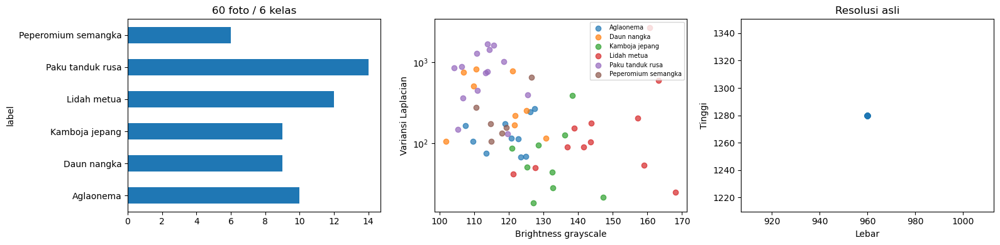

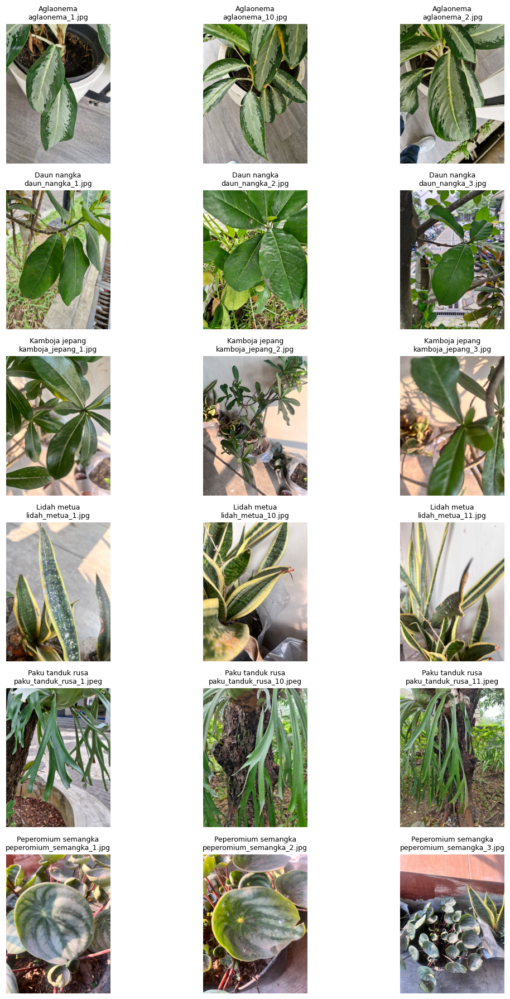

Tinjau semua label, khususnya foto dengan beberapa jenis tanaman. Tidak ada asumsi identitas botani/UB dari gambar.


In [2]:
meta = pd.read_csv(ROOT/'Dataset/metadata.csv')
assert {'image','label'} <= set(meta.columns)
assert not meta[['image','label']].isna().any().any()
assert not meta.image.duplicated().any(), 'image_id harus unik.'
meta['path'] = [str(ROOT/'Dataset'/str(r.label)/str(r.image)) for r in meta.itertuples()]
records = []
for r in meta.itertuples():
    p = Path(r.path)
    assert p.is_file(), p
    with Image.open(p) as im:
        rgb = np.asarray(ImageOps.exif_transpose(im).convert('RGB'))
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    records.append(dict(width=rgb.shape[1], height=rgb.shape[0], aspect=rgb.shape[1]/rgb.shape[0],
        brightness=float(gray.mean()), blur_laplacian=float(cv2.Laplacian(gray, cv2.CV_64F).var()),
        pixel_hash=hashlib.sha256(str(rgb.shape).encode()+rgb.tobytes()).hexdigest()))
meta = pd.concat([meta, pd.DataFrame(records)], axis=1)

if REFERENCE_ACTIVE:
    reference_meta = github_read_csv('manifest_audit.csv')
    if set(meta.image) != set(reference_meta.image):
        raise ValueError('Daftar foto tidak sama dengan eksperimen GitHub.')
    meta = meta.set_index('image').loc[reference_meta.image].reset_index()
    for key in ('label','pixel_hash'):
        if not np.array_equal(meta[key].astype(str).to_numpy(),reference_meta[key].astype(str).to_numpy()):
            raise ValueError('Foto/label berbeda dari GitHub: '+key)
    print('Urutan, label, dan hash piksel seluruh foto cocok dengan manifest GitHub.')

assert meta.groupby('pixel_hash').label.nunique().max() == 1, 'Duplikat dengan label konflik: perbaiki dahulu.'
counts = meta.groupby('label').size().rename('jumlah_foto')
display(counts.to_frame(), meta.groupby('label')[['width','height','brightness','blur_laplacian']].agg(['min','median','max']))
display(meta[meta.pixel_hash.duplicated(keep=False)][['image','label','pixel_hash']])
fig, ax = plt.subplots(1,3,figsize=(16,4))
counts.plot.barh(ax=ax[0], title=f'{len(meta)} foto / {len(counts)} kelas')
for label, d in meta.groupby('label'):
    ax[1].scatter(d.brightness, d.blur_laplacian, label=label, alpha=.7)
ax[1].set(xlabel='Brightness grayscale', ylabel='Variansi Laplacian', yscale='symlog')
ax[1].legend(fontsize=7)
ax[2].scatter(meta.width, meta.height); ax[2].set(xlabel='Lebar',ylabel='Tinggi',title='Resolusi asli')
plt.tight_layout(); plt.show()
meta.to_csv(OUT/'manifest_audit.csv', index=False)
fig, axes = plt.subplots(len(counts), 3, figsize=(12,3*len(counts)), squeeze=False)
for row,(label,d) in enumerate(meta.groupby('label')):
    for col,(_,r) in enumerate(d.head(3).iterrows()):
        with Image.open(r.path) as im:
            axes[row,col].imshow(ImageOps.exif_transpose(im))
        axes[row,col].set_title(f'{label}\n{r.image}', fontsize=9)
    for a in axes[row]: a.axis('off')
plt.tight_layout(); plt.show()
print('Tinjau semua label, khususnya foto dengan beberapa jenis tanaman. Tidak ada asumsi identitas botani/UB dari gambar.')

### 1b. Contoh augmentasi dan protokol train-only

Panel menampilkan foto asli dan enam varian untuk satu foto tiap kelas. Gaussian noise sigma 3-10, flip H/V, rotasi 90/180/270 (tanpa crop atau padding sintetis), salt-and-pepper ringan sebagai corruption, brightness +/-10-20, contrast faktor 0,85-1,15 adalah konfigurasi kandidat.

SVM/RF memakai batch fit: citra dibuat saat persiapan fit, bukan per epoch. Satu foto train menghasilkan asli + enam varian. Augmentasi dilakukan sebelum PCD, hanya dari inner-train saat tuning dan outer-train saat final fit; validation/test tetap asli. Pratinjau EDA tidak menambahkan sampel ke metadata atau split.

Kamus BoVW hanya belajar dari foto asli train, lalu dipakai juga untuk varian. Imputer/scaler/model belajar dari fitur asli + varian train. Fitur augmentasi di-cache untuk konsistensi kandidat grid. Hasil `_aug` terpisah dari baseline; bandingkan dengan split dan seed sama. Augmentasi tidak menambah individu tanaman independen, dan skor tinggi/rendah saja belum membuktikan overfitting.


Pratinjau memakai panel besar 2 x 4 untuk satu foto. Mode `illustration` memperkuat efek khusus tampilan EDA, dengan parameter tertulis pada gambar. Mode `training` menampilkan konfigurasi training yang sebenarnya. Pengaturan contoh visual ini tidak mengubah intensitas augmentasi training. Corruption ditampilkan sebagai salt-and-pepper dan disertai detail piksel yang berubah.


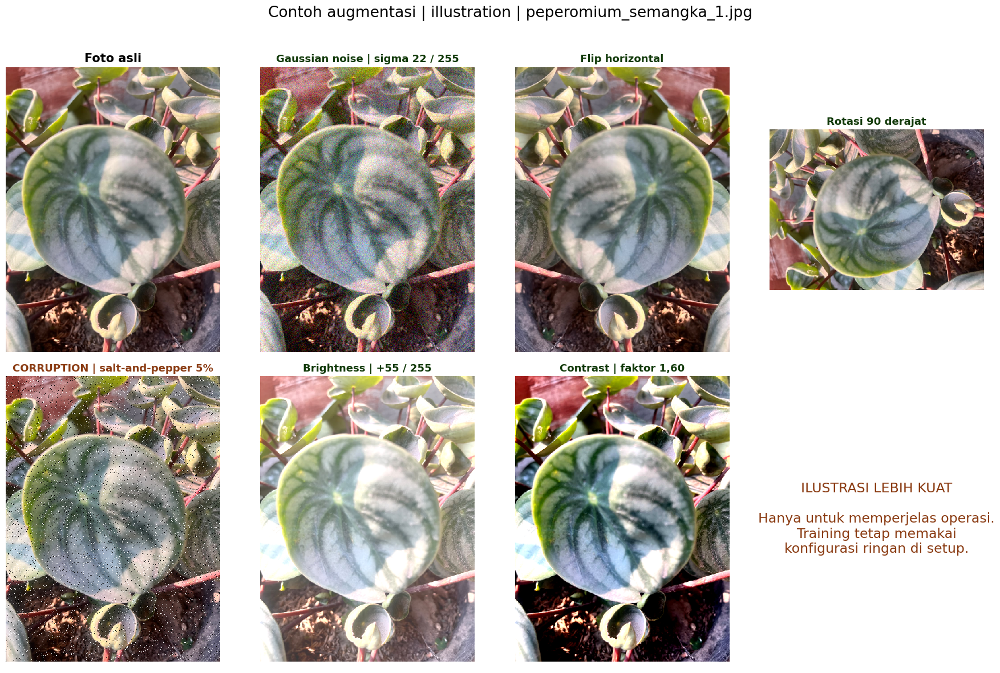

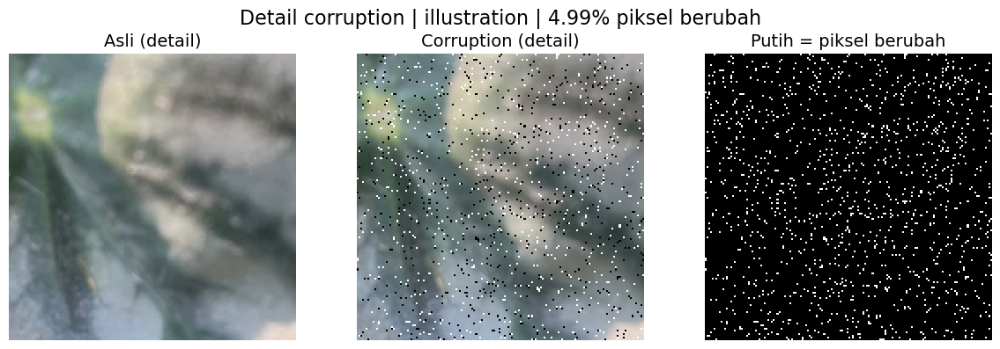

Pratinjau: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\eda_augmentasi_illustration.png
Detail corruption: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\eda_corruption_detail_illustration.png
Mode EDA tidak mengubah AUGMENT_CONFIG atau proses training.


In [3]:
def augment_rgb(rgb,kind,rng):
    """Konfigurasi kandidat; mengubah array baru, bukan file sumber."""
    x=rgb.astype(np.float32)
    if kind=='gaussian_noise':
        x+=rng.normal(0,rng.uniform(*AUGMENT_CONFIG['noise_sigma']),x.shape).astype(np.float32)
    elif kind=='flip':
        x=np.flip(x,axis=int(rng.integers(0,2))).copy()
    elif kind=='rotation':
        x=np.rot90(x,k=int(rng.integers(1,4))).copy()
    elif kind=='corruption':
        fraction=rng.uniform(*AUGMENT_CONFIG['corruption_fraction'])
        u=rng.random(x.shape[:2]); x[u<fraction/2]=0; x[(u>=fraction/2)&(u<fraction)]=255
    elif kind=='brightness':
        x+=rng.uniform(*AUGMENT_CONFIG['brightness_delta'])*rng.choice([-1.,1.])
    elif kind=='contrast':
        center=x.mean(axis=(0,1),keepdims=True)
        x=(x-center)*rng.uniform(*AUGMENT_CONFIG['contrast_factor'])+center
    else: raise ValueError(kind)
    return np.ascontiguousarray(np.clip(np.rint(x),0,255).astype(np.uint8))

# Panel besar untuk menjelaskan operasi augmentasi.
# 'illustration' lebih kuat agar terlihat jelas. 'training' memakai fungsi training persis.
EDA_AUGMENT_MODE = 'illustration'
EDA_EXAMPLE_IMAGE = 'peperomium_semangka_1.jpg'
assert EDA_AUGMENT_MODE in ('illustration','training')
eda_choice=meta.loc[meta.image.eq(EDA_EXAMPLE_IMAGE)]
assert not eda_choice.empty, 'Ubah EDA_EXAMPLE_IMAGE ke nama foto yang ada di metadata.'
eda_record=eda_choice.iloc[0]
with Image.open(eda_record.path) as eda_im:
    eda_im=ImageOps.exif_transpose(eda_im).convert('RGB')
    eda_im.thumbnail((640,640))
    eda_rgb=np.asarray(eda_im).copy()

def eda_illustration(rgb,kind,rng):
    # Fungsi ini khusus pratinjau, tidak dipanggil oleh training_matrix.
    x=rgb.astype(np.float32)
    if kind=='gaussian_noise':
        x+=rng.normal(0,22,x.shape).astype(np.float32)
        text='Gaussian noise | sigma 22 / 255'
    elif kind=='flip':
        x=np.flip(x,axis=1).copy();text='Flip horizontal'
    elif kind=='rotation':
        x=np.rot90(x,1).copy();text='Rotasi 90 derajat'
    elif kind=='corruption':
        u=rng.random(x.shape[:2]);x[u<.025]=0;x[(u>=.025)&(u<.05)]=255
        text='CORRUPTION | salt-and-pepper 5%'
    elif kind=='brightness':
        x+=55;text='Brightness | +55 / 255'
    elif kind=='contrast':
        mean=x.mean(axis=(0,1),keepdims=True)
        x=(x-mean)*1.6+mean;text='Contrast | faktor 1,60'
    else: raise ValueError(kind)
    return np.ascontiguousarray(np.clip(np.rint(x),0,255).astype(np.uint8)),text

eda_labels={'gaussian_noise':'Gaussian noise | sigma '+str(AUGMENT_CONFIG['noise_sigma']),
    'flip':'Flip horizontal / vertikal','rotation':'Rotasi 90 / 180 / 270 derajat',
    'corruption':'CORRUPTION | salt-and-pepper '+str(AUGMENT_CONFIG['corruption_fraction']),
    'brightness':'Brightness | +/- '+str(AUGMENT_CONFIG['brightness_delta']),
    'contrast':'Contrast | faktor '+str(AUGMENT_CONFIG['contrast_factor'])}
eda_variants={}
eda_fig,eda_axes=plt.subplots(2,4,figsize=(18,12),squeeze=False)
eda_axes.flat[0].imshow(eda_rgb,interpolation='nearest')
eda_axes.flat[0].set_title('Foto asli',fontsize=15,fontweight='bold')
for eda_index,eda_kind in enumerate(AUGMENT_TYPES,1):
    eda_rng=np.random.default_rng(np.random.SeedSequence([SEED,int(eda_choice.index[0]),eda_index,0]))
    if EDA_AUGMENT_MODE=='illustration':
        eda_result,eda_label=eda_illustration(eda_rgb,eda_kind,eda_rng)
    else:
        eda_result=augment_rgb(eda_rgb,eda_kind,eda_rng);eda_label=eda_labels[eda_kind]
    eda_variants[eda_kind]=eda_result
    eda_axes.flat[eda_index].imshow(eda_result,interpolation='nearest')
    eda_axes.flat[eda_index].set_title(eda_label,fontsize=13,fontweight='bold',
        color='#8A3B12' if eda_kind=='corruption' else '#123A0A')
eda_message=('ILUSTRASI LEBIH KUAT\n\nHanya untuk memperjelas operasi.\nTraining tetap memakai\nkonfigurasi ringan di setup.'
             if EDA_AUGMENT_MODE=='illustration' else
             'KONFIGURASI TRAINING\n\nVarian dibuat dengan fungsi\naugment_rgb yang sama\ndengan training.')
eda_axes.flat[7].text(.5,.5,eda_message,ha='center',va='center',fontsize=17,
    color='#8A3B12' if EDA_AUGMENT_MODE=='illustration' else '#123A0A',transform=eda_axes.flat[7].transAxes)
for eda_ax in eda_axes.flat:eda_ax.axis('off')
eda_fig.suptitle('Contoh augmentasi | '+EDA_AUGMENT_MODE+' | '+str(eda_record.image),fontsize=19)
eda_fig.tight_layout(rect=(0,0,1,.96))
eda_output=OUT/('eda_augmentasi_'+EDA_AUGMENT_MODE+'.png')
eda_fig.savefig(eda_output,dpi=140,bbox_inches='tight')
plt.show();plt.close(eda_fig)

# Detail corruption pada area tengah yang sama, tanpa memperbesar intensitas lagi.
eda_corrupt=eda_variants['corruption'];eda_h,eda_w=eda_rgb.shape[:2]
eda_y=max(0,(eda_h-160)//2);eda_x=max(0,(eda_w-160)//2)
eda_crop=(slice(eda_y,eda_y+160),slice(eda_x,eda_x+160))
eda_changed=np.any(eda_corrupt!=eda_rgb,axis=2)
eda_detail,eda_detail_axes=plt.subplots(1,3,figsize=(12,4))
eda_detail_axes[0].imshow(eda_rgb[eda_crop],interpolation='nearest')
eda_detail_axes[1].imshow(eda_corrupt[eda_crop],interpolation='nearest')
eda_detail_axes[2].imshow(eda_changed[eda_crop],cmap='gray',vmin=0,vmax=1,interpolation='nearest')
for eda_ax,eda_title in zip(eda_detail_axes,['Asli (detail)','Corruption (detail)','Putih = piksel berubah']):
    eda_ax.set_title(eda_title,fontsize=14);eda_ax.axis('off')
eda_detail.suptitle(f'Detail corruption | {EDA_AUGMENT_MODE} | {100*eda_changed.mean():.2f}% piksel berubah',fontsize=16)
eda_detail.tight_layout()
eda_detail_output=OUT/('eda_corruption_detail_'+EDA_AUGMENT_MODE+'.png')
eda_detail.savefig(eda_detail_output,dpi=140,bbox_inches='tight')
plt.show();plt.close(eda_detail)
print('Pratinjau:',eda_output)
print('Detail corruption:',eda_detail_output)
print('Mode EDA tidak mengubah AUGMENT_CONFIG atau proses training.')


## 2. Protokol split dan kontrol kebocoran

Outer CV menyimpan prediksi out-of-fold (OOF) untuk setiap kombinasi. Inner CV memilih parameter hanya dari outer-train. Split identik untuk seluruh input/paket/model; kamus BoVW di-fit ulang pada inner-train, lalu outer-train. `plant_id` dipakai bila lengkap; grup yang terlalu sedikit menghentikan evaluasi dengan pesan, bukan diam-diam beralih ke foto. Tanpa `plant_id`, exact duplicate dikelompokkan; foto terkait yang tidak identik masih dapat bocor dan harus dilengkapi metadata tanamannya.

Untuk kontrol fitur, profil ekstraksi dipilih pada inner CV **K0–F8–SVM sebagai anchor**, lalu dibekukan bersama untuk semua 108 kombinasi dalam outer fold. Ini pencarian terbatas yang terkontrol, bukan optimasi seluruh parameter tiap perlakuan. Parameter PCD dibekukan *a priori* sebagai kandidat awal MD: CLAHE L* 1,5 / 8×8, tanpa smoothing; K-Means Lab K=4; morfologi 3×3. Tidak diklaim sebagai parameter PCD terbaik. Ruang pencarian dapat diperluas dengan mengubah protokol sebelum evaluasi, bukan setelah melihat hasil OOF.

Mode reproduksi juga memakai outer split GitHub dan urutan metadata yang sama. Inner split direkonstruksi dengan seed 43?47 pada scikit-learn versi yang sama.


In [4]:
y = meta.label.to_numpy()
LABELS = sorted(meta.label.unique())
has_plants = 'plant_id' in meta and meta.plant_id.notna().all() and meta.plant_id.astype(str).str.strip().ne('').all()
if 'plant_id' in meta and not has_plants:
    raise ValueError('plant_id terisi sebagian: lengkapi seluruhnya atau hapus kolom untuk eksplorasi foto yang dinyatakan jelas.')
GROUPED = has_plants or meta.pixel_hash.duplicated().any()
groups = meta.plant_id.astype(str).to_numpy() if has_plants else meta.pixel_hash.to_numpy()
PROTOCOL = 'plant-group CV' if has_plants else 'EKSPLORATIF foto (duplikat identik satu grup)'
print(PROTOCOL)
if 'status_QC_label' in meta:
    assert meta.status_QC_label.eq('approved').all(), 'Selesaikan QC label pada seluruh daftar benchmark.'
else:
    warnings.warn('status_QC_label belum tersedia; hasil bersifat provisional.')

def split_indices(indices, n_splits, seed):
    indices = np.asarray(indices)
    if GROUPED:
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        iterator = cv.split(indices, y[indices], groups[indices])
    else:
        cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        iterator = cv.split(indices, y[indices])
    result = []
    for a,b in iterator:
        tr,va = indices[a],indices[b]
        if set(y[tr]) != set(LABELS) or set(y[va]) != set(LABELS):
            raise ValueError('Grup/foto tidak cukup untuk semua kelas pada fold train dan evaluasi. Tambah individu atau sesuaikan fold.')
        assert not set(meta.iloc[tr].pixel_hash) & set(meta.iloc[va].pixel_hash)
        if GROUPED: assert not set(groups[tr]) & set(groups[va])
        result.append((tr,va))
    return result

if REFERENCE_ACTIVE:
    saved_splits = github_read_csv('splits.csv')
    if set(saved_splits.fold) != set(range(OUTER_FOLDS)):
        raise ValueError('Jumlah outer fold berbeda dari artefak GitHub.')
    lookup = {str(image):i for i,image in enumerate(meta.image)}
    outer = []
    for fold in range(OUTER_FOLDS):
        table = saved_splits[saved_splits.fold.eq(fold)]
        if table.image.duplicated().any() or set(table.image) != set(meta.image) or set(table.role) != {'train','evaluation'}:
            raise ValueError('Split GitHub tidak lengkap atau berulang.')
        tr,te = (np.array([lookup[str(image)] for image in table.loc[table.role.eq(role),'image']],dtype=int)
                 for role in ('train','evaluation'))
        if set(tr)&set(te) or set(meta.iloc[tr].pixel_hash)&set(meta.iloc[te].pixel_hash):
            raise ValueError('Ada kebocoran train/evaluation.')
        if GROUPED and set(groups[tr])&set(groups[te]):
            raise ValueError('Ada grup tanaman yang bocor antar subset.')
        if any(str(row.group)!=str(groups[lookup[str(row.image)]]) for row in table.itertuples()):
            raise ValueError('Grup foto berubah dari split GitHub.')
        outer.append((tr,te))
    if sorted(np.concatenate([te for _,te in outer]).tolist()) != list(range(len(meta))):
        raise ValueError('Foto harus menjadi outer-evaluation tepat sekali.')
    # Inner split tidak disimpan oleh run GitHub, direkonstruksi untuk dokumentasi saja.
    # Tuning/model tidak dijalankan ulang dalam mode artefak.
    inner = {f:split_indices(tr, INNER_FOLDS, SEED+f+1) for f,(tr,te) in enumerate(outer)}
    print('Outer split dimuat langsung dari GitHub. '+('Profil/parameter memakai pilihan tersimpan.' if USE_GITHUB_ARTIFACTS else 'Profil dan parameter model akan dipilih ulang melalui inner CV.'))
else:
    outer = split_indices(np.arange(len(meta)), OUTER_FOLDS, SEED)
    inner = {f:split_indices(tr, INNER_FOLDS, SEED+f+1) for f,(tr,te) in enumerate(outer)}
split_rows = [dict(fold=f, image=meta.iloc[i].image, role=role, group=groups[i])
              for f,(tr,te) in enumerate(outer) for role,idx in [('train',tr),('evaluation',te)] for i in idx]
pd.DataFrame(split_rows).to_csv(OUT/'splits.csv',index=False)
CONDITIONS = {'N':('K0',False,None), 'E':('K1',True,None),
    'S-O':('K2',False,'otsu'), 'S-K':('K2',False,'kmeans'),
    'E-S-O':('K3',True,'otsu'), 'E-S-K':('K3',True,'kmeans')}
PACKAGES = {'F0':('color',), 'F1':('color','sobel'), 'F2':('color','canny'),
    'F3':('bovw',), 'F4':('color','bovw'), 'F5':('canny','bovw'),
    'F6':('sobel','bovw'), 'F7':('color','canny','bovw'), 'F8':('color','sobel','bovw')}
PROFILES = [dict(bins=(12,6,6), words=20, low=50, high=100),
            dict(bins=(8,4,4), words=10, low=30, high=80),
            dict(bins=(16,8,8), words=40, low=80, high=160)]
if SMOKE_TEST: PROFILES = PROFILES[:1]
display(pd.DataFrame([dict(input=k,condition=v[0],enhancement=v[1],segmenter=v[2]) for k,v in CONDITIONS.items()]))
if REPRODUCE_GITHUB_RUN:
    expected_profiles=[dict(bins=(12,6,6),words=20,low=50,high=100),
                       dict(bins=(8,4,4),words=10,low=30,high=80),
                       dict(bins=(16,8,8),words=40,low=80,high=160)]
    if PROFILES != expected_profiles:
        raise ValueError('Kandidat profil fitur berbeda dari run GitHub.')
    inner_rows=[dict(fold=f,inner_fold=j,image=meta.iloc[i].image,role=role)
        for f,folds in inner.items() for j,(tr,va) in enumerate(folds)
        for role,idx in [('train',tr),('validation',va)] for i in idx]
    pd.DataFrame(inner_rows).to_csv(OUT/'inner_splits.csv',index=False)


EKSPLORATIF foto (duplikat identik satu grup)
Outer split dimuat langsung dari GitHub. Profil dan parameter model akan dipilih ulang melalui inner CV.


e:\PCD\Project Akhir\.cache\tmp\ipykernel_6596\3566101694.py:13: UserWarning: status_QC_label belum tersedia; hasil bersifat provisional.
  warnings.warn('status_QC_label belum tersedia; hasil bersifat provisional.')


,input,condition,enhancement,segmenter
0,N,K0,False,None
1,E,K1,True,None
2,S-O,K2,False,otsu
3,S-K,K2,False,kmeans
4,E-S-O,K3,True,otsu
5,E-S-K,K3,True,kmeans


## 3. PCD full frame dan QC mask

Aturan K-Means awal yang eksplisit: centroid dengan a* < 128 digabung sebagai kandidat hijau; bila tidak ada, ambil centroid a* terkecil. Ini prior warna lintas kelas, **bukan** deteksi semantik daun atau hasil kalibrasi ROI lama. Sampel piksel deterministik dipakai untuk fit per gambar, kemudian seluruh piksel dipetakan ke centroid. K/seed/aturan yang sama dipakai pada K2 dan K3.

Mask kosong/hampir penuh tetap dicatat dan foto tetap dievaluasi. Tidak mengganti mask dengan ROI, mask manual, atau seluruh frame. Tanpa GT full frame yang ditinjau, notebook tidak menghitung IoU/Dice.

,mask_fraction,mask_empty,mask_near_full,pcd_s
input,,,,
E,1.000000,0.0,0.000000,0.007373
E-S-K,0.778496,0.0,0.550000,0.025845
E-S-O,0.459881,0.0,0.000000,0.007329
N,1.000000,0.0,0.000000,0.001180
S-K,0.712269,0.0,0.316667,0.093422
S-O,0.450979,0.0,0.000000,0.002581


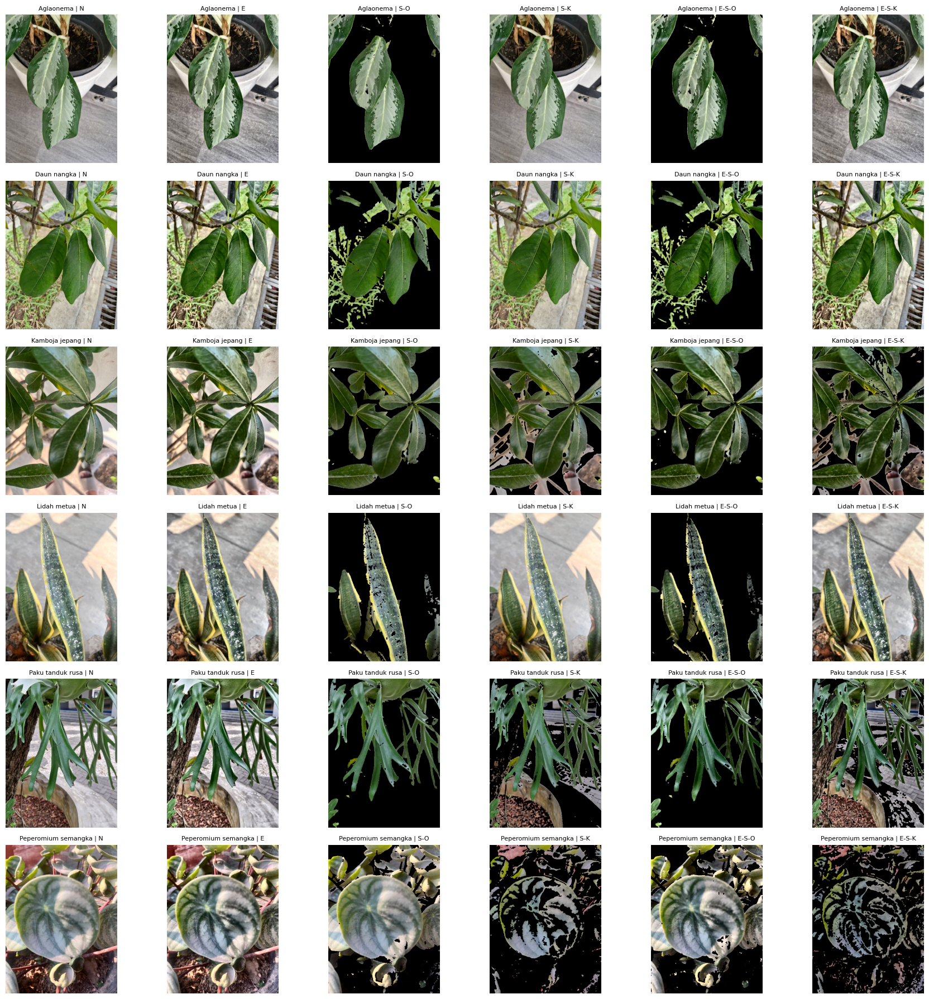

In [5]:
def process_rgb(rgb,condition):
    rgb=rgb.copy()
    _,enhance,segmenter = CONDITIONS[condition]
    if enhance:
        lab = cv2.cvtColor(rgb,cv2.COLOR_RGB2LAB)
        lab[:,:,0] = cv2.createCLAHE(clipLimit=1.5,tileGridSize=(8,8)).apply(lab[:,:,0])
        rgb = cv2.cvtColor(lab,cv2.COLOR_LAB2RGB)
    mask = np.ones(rgb.shape[:2], dtype=np.uint8)
    threshold = np.nan
    if segmenter == 'otsu':
        a = cv2.cvtColor(rgb,cv2.COLOR_RGB2LAB)[:,:,1]
        threshold, mask = cv2.threshold(a,0,1,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
    elif segmenter == 'kmeans':
        lab = cv2.cvtColor(rgb,cv2.COLOR_RGB2LAB).reshape(-1,3).astype(np.float32)
        rng = np.random.default_rng(SEED)
        sample = lab[rng.choice(len(lab),min(len(lab),5000),replace=False)]
        km = MiniBatchKMeans(n_clusters=4,random_state=SEED,n_init=3,batch_size=512).fit(sample)
        foreground = np.flatnonzero(km.cluster_centers_[:,1] < 128)
        if len(foreground)==0: foreground = [km.cluster_centers_[:,1].argmin()]
        mask = np.isin(km.predict(lab),foreground).reshape(rgb.shape[:2]).astype(np.uint8)
    if segmenter:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(3,3))
        mask = cv2.morphologyEx(mask,cv2.MORPH_OPEN,kernel)
        mask = cv2.morphologyEx(mask,cv2.MORPH_CLOSE,kernel)
    return rgb,mask.astype(bool),threshold

LOAD_TIMES = {}
@lru_cache(maxsize=12 if USE_GITHUB_ARTIFACTS else None)
def load_rgb(i):
    clock = time.perf_counter()
    with Image.open(meta.iloc[i].path) as im:
        im = ImageOps.exif_transpose(im).convert('RGB')
        w,h = im.size
        scale = min(1., MAX_SIDE/max(w,h))
        im = im.resize((max(1,round(w*scale)), max(1,round(h*scale))), Image.Resampling.LANCZOS)
        rgb = np.asarray(im).copy()
        LOAD_TIMES[i] = time.perf_counter()-clock
        return rgb

@lru_cache(maxsize=24 if USE_GITHUB_ARTIFACTS else None)
def processed(i, condition):
    t0 = time.perf_counter()
    rgb = load_rgb(i).copy()
    decode_s = LOAD_TIMES[i]  # Biaya persiapan yang sama, termasuk pada cache hit kondisi lain.
    t0 = time.perf_counter()
    rgb,mask,threshold = process_rgb(rgb,condition)
    segmenter = CONDITIONS[condition][2]
    fraction = float(mask.mean())
    return rgb, mask.astype(bool), dict(image=meta.iloc[i].image,input=condition,
        decode_resize_s=decode_s,pcd_s=time.perf_counter()-t0,mask_fraction=fraction,
        mask_empty=fraction==0,mask_near_full=bool(segmenter and fraction>.98),
        otsu_threshold=threshold)

qc = pd.DataFrame([processed(i,c)[2] for c in CONDITIONS for i in range(len(meta))])
qc.to_csv(OUT/'qc_pcd.csv', index=False)
display(qc.groupby('input')[['mask_fraction','mask_empty','mask_near_full','pcd_s']].mean())
fig, axes = plt.subplots(len(LABELS),6,figsize=(18,3*len(LABELS)),squeeze=False)
for row,label in enumerate(LABELS):
    i = int(meta.index[meta.label.eq(label)][0])
    for col,c in enumerate(CONDITIONS):
        rgb,mask,_ = processed(i,c)
        axes[row,col].imshow(np.where(mask[:,:,None],rgb,0))
        axes[row,col].set_title(f'{label} | {c}',fontsize=8); axes[row,col].axis('off')
plt.tight_layout(); plt.show()

## 4. Ekstraksi warna, edge, dan SIFT → BoVW

Warna: histogram marginal HSV + mean/std/skewness S dan V (skewness nol bila variansi nol); seluruh H tetap dihitung termasuk saturasi rendah, aturan tetap pada semua input. Sobel: mean/std magnitudo + histogram arah 8 bin berbobot magnitudo. Canny: density + mean magnitudo pada edge + histogram arah 8 bin. Histogram arah dinormalisasi L1; arah modulo 180°. Gaussian Canny 5×5 sigma 1; Sobel 3×3. Gradien dihitung **sebelum** background dihitamkan; domain edge dierosi radius 4 (termasuk frame) sesuai dukungan Gaussian+Sobel.

SIFT dihitung pada grayscale kondisi, bukan peta edge. Keypoint hanya diterima bila dukungan patch konservatif (radius ceil(6 × keypoint.size)) berada di domain; patch yang memotong mask/frame ditolak. Maksimal 100 deskriptor/foto smoke, 300 full. BoVW memakai kamus train bersama antar F3–F8, encoding L1. Tanpa keypoint → nol; domain kosong → fitur terkait NaN, diimputasi median train (kolom train seluruhnya kosong dipertahankan sebagai nol). Jika total deskriptor train < ukuran kamus, konfigurasi dihentikan dengan pesan; tidak meminjam test.

Profil pencarian memasangkan bin warna, V, dan threshold Canny pada tiga kandidat, bukan grid Cartesian penuh. Dimensi contoh profil awal: **30/40/40/20/50/30/30/60/60**; dimensi aktual dicatat per fold.

In [6]:
def hist_orientation(mag,theta,domain):
    h = np.histogram(theta[domain],bins=8,range=(0,180),weights=mag[domain])[0].astype(float)
    return h/max(h.sum(),1e-12)

def extract_rgb_features(rgb,mask,pid,source_seed):
    p = PROFILES[pid]
    clock = time.perf_counter()
    hsv = cv2.cvtColor(rgb,cv2.COLOR_RGB2HSV).astype(float)
    color = []
    for ch,bins,limit in zip(range(3),p['bins'],(180,256,256)):
        h = np.histogram(hsv[:,:,ch][mask],bins=bins,range=(0,limit))[0].astype(float)
        color.extend(h/max(h.sum(),1))
    for ch in (1,2):
        vals = hsv[:,:,ch][mask]/255
        mean = float(vals.mean()) if len(vals) else np.nan
        std = float(vals.std()) if len(vals) else np.nan
        skew = float(np.mean(((vals-mean)/std)**3)) if len(vals) and std>1e-8 else 0.
        color.extend([mean,std,skew])
    color = np.array(color) if mask.any() else np.full(sum(p['bins'])+6,np.nan)
    color_s = time.perf_counter()-clock
    clock = time.perf_counter()
    gray = cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
    domain = cv2.erode(mask.astype(np.uint8),np.ones((9,9),np.uint8),borderType=cv2.BORDER_CONSTANT,borderValue=0).astype(bool)
    def gradients(img):
        gx = cv2.Sobel(img,cv2.CV_32F,1,0,ksize=3)
        gy = cv2.Sobel(img,cv2.CV_32F,0,1,ksize=3)
        return cv2.magnitude(gx,gy), np.mod(np.degrees(np.arctan2(gy,gx)),180)
    mag,theta = gradients(gray)
    sobel = np.r_[mag[domain].mean(),mag[domain].std(),hist_orientation(mag,theta,domain)] if domain.any() else np.full(10,np.nan)
    sobel_s = time.perf_counter()-clock
    clock = time.perf_counter()
    smooth = cv2.GaussianBlur(gray,(5,5),1.)
    mag,theta = gradients(smooth)
    edges = cv2.Canny(smooth,p['low'],p['high'],apertureSize=3,L2gradient=True)>0
    selected = domain & edges
    canny = np.r_[selected.sum()/domain.sum(),mag[selected].mean() if selected.any() else 0.,hist_orientation(mag,theta,selected)] if domain.any() else np.full(10,np.nan)
    canny_s = time.perf_counter()-clock
    clock = time.perf_counter()
    sift = cv2.SIFT_create(nfeatures=300 if SMOKE_TEST else 1200)
    kp,desc = sift.detectAndCompute(gray,mask.astype(np.uint8)*255)
    distance = cv2.distanceTransform(np.pad(mask.astype(np.uint8),1),cv2.DIST_L2,5)[1:-1,1:-1]
    keep = [j for j,k in enumerate(kp) if distance[min(round(k.pt[1]),gray.shape[0]-1),min(round(k.pt[0]),gray.shape[1]-1)] > np.ceil(6*k.size)]
    desc = desc[keep] if desc is not None and keep else np.empty((0,128),np.float32)
    limit = 100 if SMOKE_TEST else 300
    if len(desc)>limit:
        desc = desc[np.random.default_rng(SEED+source_seed).choice(len(desc),limit,replace=False)]
    return dict(color=color,sobel=sobel,canny=canny,desc=desc,
        timing=dict(color=color_s,sobel=sobel_s,canny=canny_s,bovw=time.perf_counter()-clock))

@lru_cache(maxsize=32 if USE_GITHUB_ARTIFACTS else None)
def raw_features(i,c,pid):
    rgb,mask,_=processed(i,c)
    return extract_rgb_features(rgb,mask,pid,int(i))

_bovw_models={}

@lru_cache(maxsize=None)
def encode(c,pid,train_tuple):
    if USE_GITHUB_ARTIFACTS and not RUN_NEW_DIAGNOSTIC_MODELS:
        raise RuntimeError('Kamus BoVW tidak tersimpan di GitHub. Rekonstruksi hanya untuk eksperimen diagnostik baru yang diaktifkan eksplisit.')
    t0 = time.perf_counter()
    data = [raw_features(i,c,pid) for i in range(len(meta))]
    descriptors = np.concatenate([data[i]['desc'] for i in train_tuple],axis=0)
    v = PROFILES[pid]['words']
    if len(descriptors)<v:
        raise ValueError(f'{c}: hanya {len(descriptors)} deskriptor train untuk V={v}. Kurangi V a priori/tambah data, jangan memakai test.')
    km = MiniBatchKMeans(n_clusters=v,random_state=SEED,n_init=3,batch_size=512).fit(descriptors)
    _bovw_models[(c,pid,train_tuple)]=km
    bovw, encoding_s = [], []
    for d in data:
        clock = time.perf_counter()
        h = np.bincount(km.predict(d['desc']),minlength=v).astype(float) if len(d['desc']) else np.zeros(v)
        bovw.append(h/max(h.sum(),1)); encoding_s.append(time.perf_counter()-clock)
    blocks = {k:np.vstack([d[k] for d in data]) for k in ('color','sobel','canny')}
    blocks['bovw'] = np.vstack(bovw)
    return blocks,np.array(encoding_s),time.perf_counter()-t0

def matrix(c,pid,train,f):
    blocks,_,_ = encode(c,pid,tuple(map(int,train)))
    return np.concatenate([blocks[k] for k in PACKAGES[f]],axis=1)

def names(pid,f):
    p = PROFILES[pid]
    color = [f'color_{ch}_bin{j:02}' for ch,b in zip('HSV',p['bins']) for j in range(b)]
    color += [f'color_{ch}_{stat}' for ch in 'SV' for stat in ('mean','std','skew')]
    blocks = dict(color=color,sobel=['sobel_mean','sobel_std']+[f'sobel_orientation{j}' for j in range(8)],
        canny=['canny_density','canny_mean_magnitude']+[f'canny_orientation{j}' for j in range(8)],
        bovw=[f'bovw_word{j:02}' for j in range(p['words'])])
    return [n for k in PACKAGES[f] for n in blocks[k]]

def estimator(model,param):
    imputer = SimpleImputer(strategy='median',keep_empty_features=True)
    if model=='SVM': return make_pipeline(imputer,StandardScaler(),SVC(kernel='rbf',**param))
    return make_pipeline(imputer,RandomForestClassifier(n_estimators=N_TREES,random_state=SEED,n_jobs=1,**param))

GRIDS = {'SVM':[dict(C=c,gamma=g) for c,g in product((.1,1,10),('scale',.01,.1))],
         'RF':[dict(max_depth=d,min_samples_leaf=l) for d,l in product((None,5,10),(1,2,4))]}
if SMOKE_TEST: GRIDS = {'SVM':[dict(C=1,gamma='scale')], 'RF':[dict(max_depth=5,min_samples_leaf=1)]}
assert [len(names(0,f)) for f in PACKAGES] == [30,40,40,20,50,30,30,60,60]

if REPRODUCE_GITHUB_RUN:
    expected_grids={'SVM':[dict(C=c,gamma=g) for c,g in product((.1,1,10),('scale',.01,.1))],
                    'RF':[dict(max_depth=d,min_samples_leaf=l) for d,l in product((None,5,10),(1,2,4))]}
    if GRIDS != expected_grids:
        raise ValueError('Grid atau urutan kandidat model berbeda dari run GitHub.')


In [7]:
@lru_cache(maxsize=96)
def augmentation_blocks(c,pid,train_tuple,config_signature):
    """On-demand train-only; cache fitur agar grid memakai varian identik."""
    encode(c,pid,train_tuple)
    km=_bovw_models[(c,pid,train_tuple)]
    blocks={k:[] for k in ('color','sobel','canny','bovw')}; sources=[]
    for source in train_tuple:
        for kind_index,kind in enumerate(AUGMENT_TYPES,1):
            for copy in range(AUGMENT_COPIES_PER_TYPE):
                rng=np.random.default_rng(np.random.SeedSequence([SEED,int(source),kind_index,copy]))
                rgb=augment_rgb(load_rgb(int(source)),kind,rng)
                rgb,mask,_=process_rgb(rgb,c)
                d=extract_rgb_features(rgb,mask,pid,int(source))
                for key in ('color','sobel','canny'): blocks[key].append(d[key])
                hist=np.bincount(km.predict(d['desc']),minlength=PROFILES[pid]['words']).astype(float) if len(d['desc']) else np.zeros(PROFILES[pid]['words'])
                blocks['bovw'].append(hist/max(hist.sum(),1)); sources.append(int(source))
    return {k:np.vstack(v) for k,v in blocks.items()},np.asarray(sources)

def training_matrix(c,pid,train,f):
    original=matrix(c,pid,train,f)[train]; labels=y[train]
    if not AUGMENTATION_ENABLED: return original,labels
    signature=json.dumps(dict(types=AUGMENT_TYPES,copies=AUGMENT_COPIES_PER_TYPE,config=AUGMENT_CONFIG),sort_keys=True)
    blocks,sources=augmentation_blocks(c,pid,tuple(map(int,train)),signature)
    assert set(sources).issubset(set(map(int,train))), 'Sumber augmentasi harus train saja.'
    augmented=np.concatenate([blocks[k] for k in PACKAGES[f]],axis=1)
    return np.vstack([original,augmented]),np.concatenate([labels,y[sources]])


## 5. Nested CV, tuning, dan 108 kombinasi ML

Full mode: jumlah outer/inner fold mengikuti konfigurasi setup; masing-masing model 9 kandidat (SVM C×gamma, RF depth×leaf), RF 200 pohon. Tidak ada augmentasi, oversampling, atau pemilihan parameter dari outer-evaluation. Smoke memakai dua outer fold, profil awal saja, satu kandidat/model, RF 12 pohon, resolusi 256; hanya menguji alur. Semua foto tetap digunakan.

Tabel skor berisi metrik per fold dan waktu inferensi per foto: PCD, ekstraksi fitur yang diperlukan paket, encoding BoVW bila digunakan, prediksi model, total termasuk decode/resize. Waktu fit dicatat terpisah. Timing dari cache mewakili satu pengukuran komponen pada mesin yang sama, bukan pengukuran deployment yang stabil; overhead I/O file hasil tidak dihitung.

Dalam mode artefak, cell berikut membaca metrik, prediksi dan profil GitHub. Loop training hanya dijalankan jika `USE_GITHUB_ARTIFACTS=False`. Output lama pada cell yang tidak berubah tetap merupakan output historis.


Pada `REPRODUCE_GITHUB_RUN=True`, cell berikut menjalankan training sesungguhnya dan membandingkan hasilnya dengan GitHub. Prediksi dan profil tidak disalin dari hasil lama.


In [8]:

def compare_retrained_run(new_metrics,new_predictions,new_profiles,reference_metrics,reference_predictions,reference_profiles,destination):
    prediction_keys=['fold','input','feature','model','image']
    metric_keys=['fold','input','feature','model']
    for table,keys in [(new_predictions,prediction_keys),(reference_predictions,prediction_keys),
                       (new_metrics,metric_keys),(reference_metrics,metric_keys)]:
        if table.duplicated(keys).any():raise ValueError('Baris evaluasi berulang.')
    joined=new_predictions[prediction_keys+['true','pred']].merge(
        reference_predictions[prediction_keys+['true','pred']],on=prediction_keys,how='outer',
        suffixes=('_new','_github'),indicator=True,validate='one_to_one')
    if not joined['_merge'].eq('both').all() or not joined.true_new.eq(joined.true_github).all():
        raise ValueError('Identitas foto/fold/label tidak sebanding dengan referensi.')
    differences=joined[joined.pred_new.ne(joined.pred_github)].drop(columns='_merge')
    compared=new_metrics[metric_keys+['accuracy','macro_f1','params']].merge(
        reference_metrics[metric_keys+['accuracy','macro_f1','params']],on=metric_keys,how='outer',
        suffixes=('_new','_github'),indicator=True,validate='one_to_one')
    if not compared['_merge'].eq('both').all():raise ValueError('Daftar konfigurasi benchmark berbeda.')
    for metric in ('accuracy','macro_f1'):
        compared[metric+'_delta']=compared[metric+'_new']-compared[metric+'_github']
        compared[metric+'_match']=np.isclose(compared[metric+'_new'],compared[metric+'_github'],rtol=0,atol=1e-12)
    compared['params_match']=[json.loads(a)==json.loads(b) for a,b in zip(compared.params_new,compared.params_github)]
    profile_pairs=lambda rows:{int(row['fold']):int(row['profile']) for row in rows}
    profiles_match=profile_pairs(new_profiles)==profile_pairs(reference_profiles)
    metrics_match=bool(compared[['accuracy_match','macro_f1_match']].to_numpy().all())
    report=dict(reference_commit=GITHUB_COMMIT,prediction_rows=len(joined),different_predictions=len(differences),
        predictions_identical=bool(differences.empty),metrics_match_atol_1e12=metrics_match,
        selected_profiles_identical=profiles_match,selected_parameters_identical=bool(compared.params_match.all()),
        performance_reproduced=bool(differences.empty and metrics_match),
        time_measurements_compared=False,model_weights_compared=False)
    destination=Path(destination);destination.mkdir(parents=True,exist_ok=True)
    differences.to_csv(destination/'reproduction_prediction_differences.csv',index=False)
    compared.drop(columns='_merge').to_csv(destination/'reproduction_metrics_comparison.csv',index=False)
    (destination/'reproduction_comparison.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
    print('Perbandingan training ulang dengan GitHub:',report)
    return report

if USE_GITHUB_ARTIFACTS:
    score_df = github_read_csv('metrics_per_fold.csv')
    pred_df = github_read_csv('oof_predictions.csv')
    selected_profiles = json.loads(github_file('selected_profiles.json').read_text(encoding='utf-8'))
    tuning_rows = github_read_csv('inner_tuning.csv').to_dict('records')
    fitted = {}  # Model terlatih tidak tersimpan dalam artefak GitHub.
    if len(score_df)!=108*len(outer) or len(pred_df)!=108*len(meta):
        raise ValueError('Jumlah metrik/prediksi tidak sesuai benchmark GitHub.')
    if not pred_df.groupby(['input','feature','model','image']).size().eq(1).all():
        raise ValueError('Prediksi OOF tidak unik.')
    for fold,(_,te) in enumerate(outer):
        table=pred_df[pred_df.fold.eq(fold)]
        if set(table.image)!=set(meta.iloc[te].image):
            raise ValueError('Fold prediksi tidak cocok dengan split GitHub.')
    truth=dict(zip(meta.image,meta.label))
    if not pred_df.true.eq(pred_df.image.map(truth)).all():
        raise ValueError('Label prediksi tidak cocok dengan metadata GitHub.')
    pred_df['correct']=pred_df.true.eq(pred_df.pred)
    print(f'Dimuat dari GitHub: {len(score_df)} baris metrik, {len(pred_df)} prediksi OOF. Tidak ada training.')
else:
    def inner_score(c,pid,f,model,param,fold):
        scores = []
        for tr,va in inner[fold]:
            X = matrix(c,pid,tr,f)
            train_X,train_y = training_matrix(c,pid,tr,f)
            est = estimator(model,param).fit(train_X,train_y)
            scores.append(f1_score(y[va],est.predict(X[va]),labels=LABELS,average='macro',zero_division=0))
        return float(np.mean(scores))

    scores, predictions, selected_profiles, tuning_rows, fitted = [], [], [], [], {}
    for fold,(tr,te) in enumerate(outer):
        anchor = [inner_score('N',pid,'F8','SVM',dict(C=1,gamma='scale'),fold) for pid in range(len(PROFILES))]
        pid = int(np.argmax(anchor))
        selected_profiles.append(dict(fold=fold,profile=pid,anchor_macro_f1=anchor[pid],**PROFILES[pid]))
        print(f'Fold {fold+1}/{len(outer)}: profil {pid}, {len(tr)} train / {len(te)} evaluasi', flush=True)
        for c in CONDITIONS:
            for f in PACKAGES:
                X = matrix(c,pid,tr,f)
                assert X.shape[1]==len(names(pid,f))
                for model in GRIDS:
                    inner_values = [inner_score(c,pid,f,model,param,fold) for param in GRIDS[model]]
                    best = int(np.argmax(inner_values)); param = GRIDS[model][best]
                    for params,value in zip(GRIDS[model],inner_values):
                        tuning_rows.append(dict(fold=fold,input=c,feature=f,model=model,params=json.dumps(params),inner_macro_f1=value))
                    prep_clock = time.perf_counter()
                    train_X,train_y = training_matrix(c,pid,tr,f)
                    augmentation_prepare_s = time.perf_counter()-prep_clock
                    clock = time.perf_counter()
                    est = estimator(model,param).fit(train_X,train_y)
                    fit_s = time.perf_counter()-clock
                    clock = time.perf_counter(); pred = est.predict(X[te]); model_s = (time.perf_counter()-clock)/len(te)
                    _,enc_s,_ = encode(c,pid,tuple(map(int,tr)))
                    pcd_s = np.mean([processed(int(i),c)[2]['pcd_s'] for i in te])
                    decode_s = np.mean([processed(int(i),c)[2]['decode_resize_s'] for i in te])
                    feature_s = np.mean([sum(raw_features(int(i),c,pid)['timing'][b] for b in PACKAGES[f]) for i in te])
                    if 'bovw' in PACKAGES[f]: feature_s += enc_s[te].mean()
                    scores.append(dict(fold=fold,input=c,condition=CONDITIONS[c][0],feature=f,model=model,profile=pid,
                        augmentation=AUGMENTATION_ENABLED,n_train_original=len(tr),n_train_fit=len(train_y),
                        augmentation_prepare_s=augmentation_prepare_s,dim=X.shape[1],accuracy=accuracy_score(y[te],pred),
                        macro_f1=f1_score(y[te],pred,labels=LABELS,average='macro',zero_division=0),
                        inner_macro_f1=inner_values[best],params=json.dumps(param),fit_s=fit_s,
                        decode_resize_s=decode_s,pcd_s=pcd_s,feature_s=feature_s,model_s=model_s,
                        total_s=decode_s+pcd_s+feature_s+model_s,
                        mask_failure_rate=float(np.mean([processed(int(i),c)[2]['mask_empty'] for i in te]))))
                    predictions.extend(dict(fold=fold,input=c,feature=f,model=model,image=meta.iloc[i].image,
                        true=y[i],pred=p,correct=bool(y[i]==p)) for i,p in zip(te,pred))
                    fitted[(fold,c,f,model)] = (est,pid)
            print(f'  {c}: selesai 18 kombinasi', flush=True)
    score_df, pred_df = pd.DataFrame(scores), pd.DataFrame(predictions)
    assert len(score_df)==108*len(outer)
    assert pred_df.groupby(['input','feature','model','image']).size().eq(1).all()
    assert len(pred_df)==108*len(meta)
    score_df.to_csv(OUT/'metrics_per_fold.csv',index=False)
    pred_df.to_csv(OUT/'oof_predictions.csv',index=False)
    pd.DataFrame(tuning_rows).to_csv(OUT/'inner_tuning.csv',index=False)
    pd.DataFrame(selected_profiles).to_json(OUT/'selected_profiles.json',orient='records',indent=2)
    print('SMOKE TEST — bukan skor benchmark final' if SMOKE_TEST else 'Nested CV selesai.')

if REPRODUCE_GITHUB_RUN:
    reproduction_report=compare_retrained_run(score_df,pred_df,selected_profiles,
        github_read_csv('metrics_per_fold.csv'),github_read_csv('oof_predictions.csv'),
        json.loads(github_file('selected_profiles.json').read_text(encoding='utf-8')),OUT)
    if not reproduction_report['performance_reproduced']:
        warnings.warn('Prediksi/skor training ulang berbeda dari run GitHub. Lihat berkas reproduction_* untuk melacak perbedaannya. Hasil baru tetap dipertahankan, tidak diganti dengan skor lama.')


Fold 1/5: profil 2, 48 train / 12 evaluasi
  N: selesai 18 kombinasi
  E: selesai 18 kombinasi
  S-O: selesai 18 kombinasi
  S-K: selesai 18 kombinasi
  E-S-O: selesai 18 kombinasi
  E-S-K: selesai 18 kombinasi
Fold 2/5: profil 2, 48 train / 12 evaluasi
  N: selesai 18 kombinasi
  E: selesai 18 kombinasi
  S-O: selesai 18 kombinasi
  S-K: selesai 18 kombinasi
  E-S-O: selesai 18 kombinasi
  E-S-K: selesai 18 kombinasi
Fold 3/5: profil 2, 48 train / 12 evaluasi
  N: selesai 18 kombinasi
  E: selesai 18 kombinasi
  S-O: selesai 18 kombinasi
  S-K: selesai 18 kombinasi
  E-S-O: selesai 18 kombinasi
  E-S-K: selesai 18 kombinasi
Fold 4/5: profil 2, 48 train / 12 evaluasi
  N: selesai 18 kombinasi
  E: selesai 18 kombinasi
  S-O: selesai 18 kombinasi
  S-K: selesai 18 kombinasi
  E-S-O: selesai 18 kombinasi
  E-S-K: selesai 18 kombinasi
Fold 5/5: profil 2, 48 train / 12 evaluasi
  N: selesai 18 kombinasi
  E: selesai 18 kombinasi
  S-O: selesai 18 kombinasi
  S-K: selesai 18 kombinasi
  E-S

## 6. Hasil ablasi berpasangan

Delta dihitung pada fold, model, dan paket yang sama. PCD: E−N; S−N; E-S−E; E-S−S untuk Otsu/K-Means. Fitur: F1/F2−F0; F4−F0; F7−F2; F8−F1; F4/F5/F6−F3; F7−F5; F8−F6. Laporkan mean dan simpangan antarfold bersama jumlah foto. Delta positif menunjukkan manfaat klasifikasi pada protokol ini, bukan bukti akurasi mask. Ranking 108 kombinasi OOF bersifat deskriptif; skor pemenang setelah melihat semua OOF optimistis sebagai estimasi model terpilih. Konfirmasi memerlukan test tanaman yang benar-benar terpisah.

,input,feature,model,macro_f1_mean,macro_f1_std,accuracy_mean,total_s
63,N,F4,SVM,0.944444,0.124226,0.966667,0.164806
69,N,F7,SVM,0.944444,0.124226,0.966667,0.179812
71,N,F8,SVM,0.944444,0.124226,0.966667,0.182862
65,N,F5,SVM,0.930000,0.074079,0.933333,0.142813
67,N,F6,SVM,0.930000,0.074079,0.933333,0.145869
22,E-S-K,F2,RF,0.903333,0.070229,0.900000,0.103408
68,N,F7,RF,0.898889,0.068539,0.900000,0.180406
14,E,F7,RF,0.895556,0.103518,0.916667,0.188784
62,N,F4,RF,0.894444,0.110972,0.900000,0.165449
20,E-S-K,F1,RF,0.891905,0.053134,0.883333,0.104357


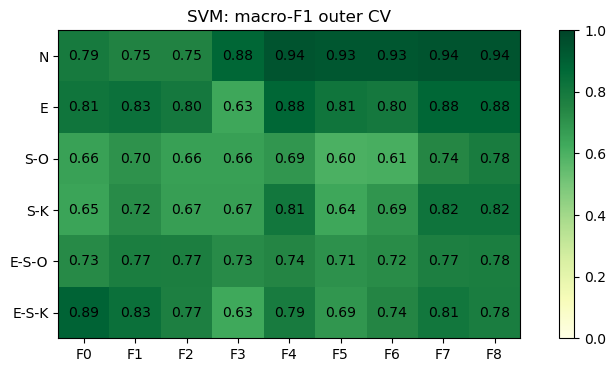

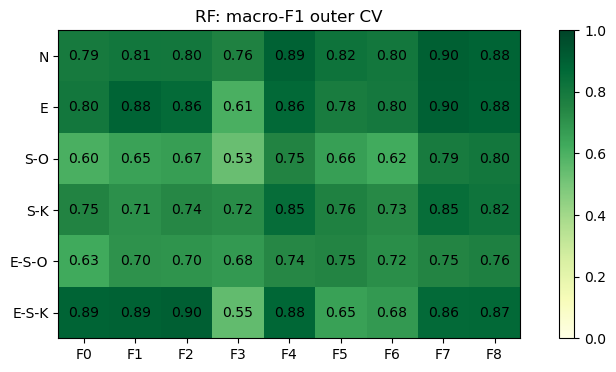

mean     std
axis    fixed model contrast                   
PCD     F0    RF    E - N        0.0122  0.0750
                    E-S-K - E    0.0840  0.0735
                    E-S-K - S-K  0.1344  0.1377
                    E-S-O - E   -0.1749  0.2145
                    E-S-O - S-O  0.0237  0.0899
...                                 ...     ...
feature S-O   SVM   F6 - F3     -0.0506  0.1933
                    F7 - F2      0.0852  0.0885
                    F7 - F5      0.1405  0.1998
                    F8 - F1      0.0821  0.0724
                    F8 - F6      0.1730  0.1613

[246 rows x 2 columns]

In [9]:
if USE_GITHUB_ARTIFACTS:
    summary = github_read_csv('summary_108.csv')
else:
    summary = score_df.groupby(['input','feature','model']).agg(
        macro_f1_mean=('macro_f1','mean'), macro_f1_std=('macro_f1','std'),
        accuracy_mean=('accuracy','mean'), total_s=('total_s','mean')).reset_index()
    summary = summary.sort_values(['macro_f1_mean','input','feature','model'],ascending=[False,True,True,True])
    summary.to_csv(OUT/'summary_108.csv',index=False)
display(summary.head(20))
for model in GRIDS:
    table = summary[summary.model.eq(model)].pivot(index='input',columns='feature',values='macro_f1_mean').reindex(CONDITIONS)
    fig,ax = plt.subplots(figsize=(10,4)); im=ax.imshow(table,vmin=0,vmax=1,cmap='YlGn')
    ax.set_xticks(range(9),table.columns); ax.set_yticks(range(6),table.index)
    for (r,k),v in np.ndenumerate(table.to_numpy()): ax.text(k,r,f'{v:.2f}',ha='center',va='center')
    ax.set_title(f'{model}: macro-F1 '+('SMOKE' if SMOKE_TEST else 'outer CV')); fig.colorbar(im,ax=ax); plt.show()
deltas=[]
for keys,d in score_df.groupby(['fold','feature','model']):
    indexed=d.set_index('input')
    for a,b in [('E','N'),('S-O','N'),('S-K','N'),('E-S-O','E'),('E-S-K','E'),('E-S-O','S-O'),('E-S-K','S-K')]:
        deltas.append(dict(axis='PCD',fold=keys[0],fixed=keys[1],model=keys[2],contrast=f'{a} - {b}',delta=indexed.loc[a,'macro_f1']-indexed.loc[b,'macro_f1']))
for keys,d in score_df.groupby(['fold','input','model']):
    indexed=d.set_index('feature')
    for a,b in [('F1','F0'),('F2','F0'),('F4','F0'),('F7','F2'),('F8','F1'),('F4','F3'),('F5','F3'),('F6','F3'),('F7','F5'),('F8','F6')]:
        deltas.append(dict(axis='feature',fold=keys[0],fixed=keys[1],model=keys[2],contrast=f'{a} - {b}',delta=indexed.loc[a,'macro_f1']-indexed.loc[b,'macro_f1']))
delta_df=pd.DataFrame(deltas); delta_df.to_csv(OUT/'paired_deltas.csv',index=False)
display(delta_df.groupby(['axis','fixed','model','contrast']).delta.agg(['mean','std']).round(4))

## 7. Error analysis: kelas paling banyak salah dan pasangan kebingungan

Pilih satu konfigurasi yang ingin dibahas (`ANALYSIS_KEY`) sebelum membaca detail kesalahan. Default menampilkan kombinasi teratas deskriptif, **bukan** test independen model terbaik. Untuk setiap model, tabel seluruh konfigurasi tetap disimpan. `jumlah_salah = support − benar` dan `error_rate = jumlah_salah / support` menjawab pertanyaan berbeda pada kelas tidak seimbang. Contoh salah diambil dari prediksi OOF, bukan prediksi training.

,kelas,support,jumlah_salah,error_rate,recall
5,Peperomium semangka,6,1,0.166667,0.833333
2,Kamboja jepang,9,1,0.111111,0.888889
0,Aglaonema,10,0,0.000000,1.000000
1,Daun nangka,9,0,0.000000,1.000000
3,Lidah metua,12,0,0.000000,1.000000
4,Paku tanduk rusa,14,0,0.000000,1.000000


Konfigurasi analisis: ('N', 'F4', 'SVM')
Kelas dengan jumlah salah terbanyak: Peperomium semangka, Kamboja jepang ; jumlah salah = 1
Kelas dengan error rate tertinggi: Peperomium semangka


,precision,recall,f1-score,support
Aglaonema,1.000000,1.000000,1.000000,10.000000
Daun nangka,1.000000,1.000000,1.000000,9.000000
Kamboja jepang,1.000000,0.888889,0.941176,9.000000
Lidah metua,0.857143,1.000000,0.923077,12.000000
Paku tanduk rusa,1.000000,1.000000,1.000000,14.000000
Peperomium semangka,1.000000,0.833333,0.909091,6.000000
accuracy,0.966667,0.966667,0.966667,0.966667
macro avg,0.976190,0.953704,0.962224,60.000000
weighted avg,0.971429,0.966667,0.966701,60.000000


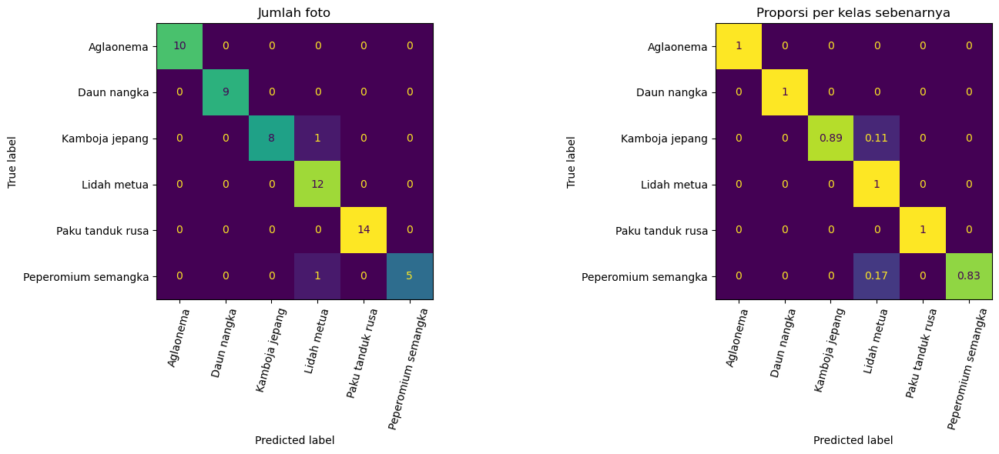

true                 pred       
Kamboja jepang       Lidah metua    1
Peperomium semangka  Lidah metua    1
Name: jumlah, dtype: int64

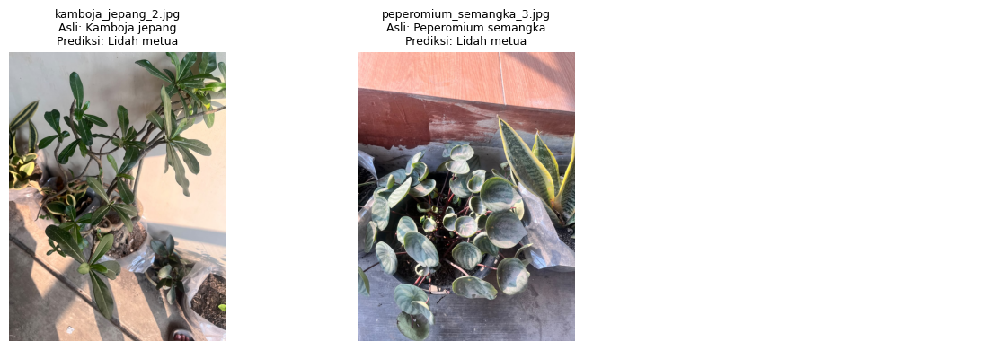

In [10]:
ANALYSIS_KEY = tuple(summary.iloc[0][['input','feature','model']])
c,f,model = ANALYSIS_KEY
def class_errors(d):
    rows=[]
    for label in LABELS:
        s=d[d.true.eq(label)]
        rows.append(dict(kelas=label,support=len(s),jumlah_salah=int((~s.correct).sum()),
            error_rate=float((~s.correct).mean()),recall=float(s.correct.mean())))
    return pd.DataFrame(rows).sort_values(['jumlah_salah','error_rate'],ascending=False)
all_class=[]
for (ci,fi,mi),d in pred_df.groupby(['input','feature','model']):
    t=class_errors(d); t['input']=ci; t['feature']=fi; t['model']=mi; all_class.append(t)
pd.concat(all_class).to_csv(OUT/'class_errors_all_108.csv',index=False)
d = pred_df[pred_df.input.eq(c)&pred_df.feature.eq(f)&pred_df.model.eq(model)].copy()
errors=class_errors(d); display(errors)
max_wrong=errors.jumlah_salah.max()
print('Konfigurasi analisis:',ANALYSIS_KEY)
print('Kelas dengan jumlah salah terbanyak:', ', '.join(errors.loc[errors.jumlah_salah.eq(max_wrong),'kelas']), '; jumlah salah =',max_wrong)
max_rate=errors.error_rate.max()
print('Kelas dengan error rate tertinggi:', ', '.join(errors.loc[errors.error_rate.eq(max_rate),'kelas']))
report=pd.DataFrame(classification_report(d.true,d.pred,labels=LABELS,output_dict=True,zero_division=0)).T
display(report); report.to_csv(OUT/'classification_report_selected.csv')
fig,axes=plt.subplots(1,2,figsize=(15,6))
for ax,norm in zip(axes,(None,'true')):
    ConfusionMatrixDisplay.from_predictions(d.true,d.pred,labels=LABELS,normalize=norm,ax=ax,xticks_rotation=75,colorbar=False)
    ax.set_title('Jumlah foto' if norm is None else 'Proporsi per kelas sebenarnya')
plt.tight_layout(); plt.show()
confusions=d[~d.correct].groupby(['true','pred']).size().rename('jumlah').sort_values(ascending=False)
display(confusions); confusions.to_csv(OUT/'confusion_pairs_selected.csv')
wrong=d[~d.correct].head(12)
if len(wrong):
    fig,axes=plt.subplots(int(np.ceil(len(wrong)/3)),3,figsize=(12,4*np.ceil(len(wrong)/3)),squeeze=False)
    for ax in axes.flat: ax.axis('off')
    for ax,r in zip(axes.flat,wrong.itertuples()):
        i=int(meta.index[meta.image.eq(r.image)][0]); rgb,mask,_=processed(i,c)
        ax.imshow(rgb); ax.contour(mask,levels=[.5],colors='yellow',linewidths=.5) if mask.any() and not mask.all() else None
        ax.set_title(f'{r.image}\nAsli: {r.true}\nPrediksi: {r.pred}',fontsize=9)
    plt.tight_layout(); plt.show()
else: print('Tidak ada kesalahan OOF pada konfigurasi ini; belum membuktikan generalisasi tanaman baru.')

### 7b. Error analysis empat konfigurasi teratas tanpa training ulang



,input,feature,model,macro_f1_mean,macro_f1_std,accuracy_mean,total_s
0,N,F4,SVM,0.944444,0.124226,0.966667,0.164806
1,N,F7,SVM,0.944444,0.124226,0.966667,0.179812
2,N,F8,SVM,0.944444,0.124226,0.966667,0.182862
3,N,F5,SVM,0.930000,0.074079,0.933333,0.142813



Peringkat 1: ('N', 'F4', 'SVM') | 60 foto OOF


,precision,recall,f1-score,support
Aglaonema,1.000000,1.000000,1.000000,10.000000
Daun nangka,1.000000,1.000000,1.000000,9.000000
Kamboja jepang,1.000000,0.888889,0.941176,9.000000
Lidah metua,0.857143,1.000000,0.923077,12.000000
Paku tanduk rusa,1.000000,1.000000,1.000000,14.000000
Peperomium semangka,1.000000,0.833333,0.909091,6.000000
accuracy,0.966667,0.966667,0.966667,0.966667
macro avg,0.976190,0.953704,0.962224,60.000000
weighted avg,0.971429,0.966667,0.966701,60.000000


,kelas,support,jumlah_salah,error_rate
5,Peperomium semangka,6,1,0.166667
2,Kamboja jepang,9,1,0.111111
1,Daun nangka,9,0,0.000000
0,Aglaonema,10,0,0.000000
3,Lidah metua,12,0,0.000000
4,Paku tanduk rusa,14,0,0.000000


,fold,profile,accuracy,macro_f1,params
8,0,2,1.000000,1.000000,"{""C"": 1, ""gamma"": 0.01}"
116,1,2,0.833333,0.722222,"{""C"": 1, ""gamma"": ""scale""}"
224,2,2,1.000000,1.000000,"{""C"": 1, ""gamma"": 0.01}"
332,3,2,1.000000,1.000000,"{""C"": 1, ""gamma"": 0.01}"
440,4,2,1.000000,1.000000,"{""C"": 1, ""gamma"": ""scale""}"


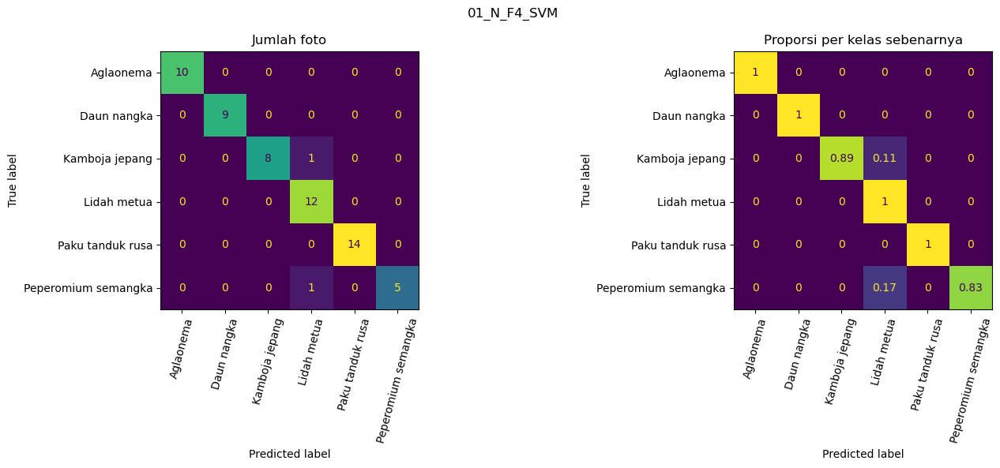

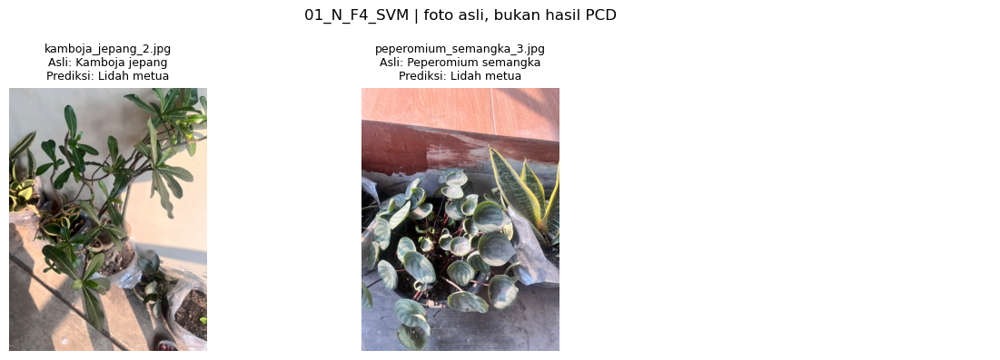


Peringkat 2: ('N', 'F7', 'SVM') | 60 foto OOF


,precision,recall,f1-score,support
Aglaonema,1.000000,1.000000,1.000000,10.000000
Daun nangka,1.000000,1.000000,1.000000,9.000000
Kamboja jepang,1.000000,0.888889,0.941176,9.000000
Lidah metua,0.857143,1.000000,0.923077,12.000000
Paku tanduk rusa,1.000000,1.000000,1.000000,14.000000
Peperomium semangka,1.000000,0.833333,0.909091,6.000000
accuracy,0.966667,0.966667,0.966667,0.966667
macro avg,0.976190,0.953704,0.962224,60.000000
weighted avg,0.971429,0.966667,0.966701,60.000000


,kelas,support,jumlah_salah,error_rate
5,Peperomium semangka,6,1,0.166667
2,Kamboja jepang,9,1,0.111111
1,Daun nangka,9,0,0.000000
0,Aglaonema,10,0,0.000000
3,Lidah metua,12,0,0.000000
4,Paku tanduk rusa,14,0,0.000000


,fold,profile,accuracy,macro_f1,params
14,0,2,1.000000,1.000000,"{""C"": 1, ""gamma"": ""scale""}"
122,1,2,0.833333,0.722222,"{""C"": 1, ""gamma"": ""scale""}"
230,2,2,1.000000,1.000000,"{""C"": 1, ""gamma"": 0.01}"
338,3,2,1.000000,1.000000,"{""C"": 1, ""gamma"": ""scale""}"
446,4,2,1.000000,1.000000,"{""C"": 1, ""gamma"": ""scale""}"


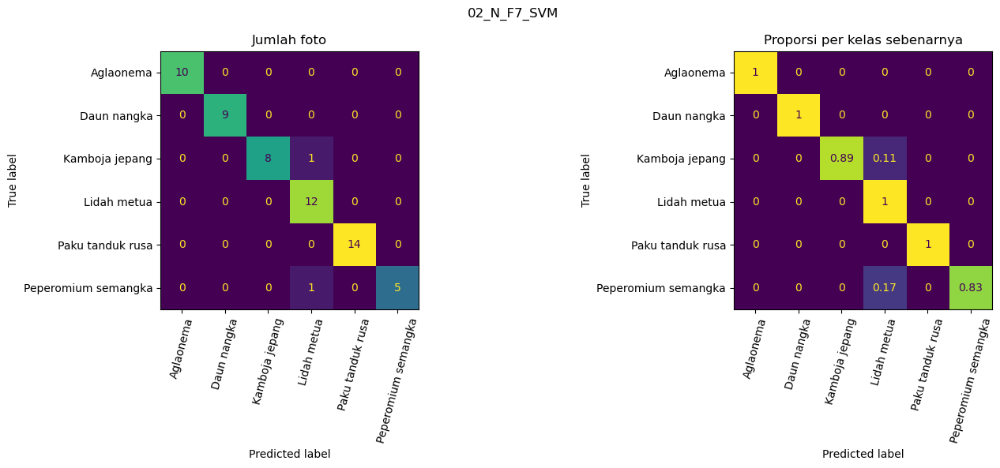

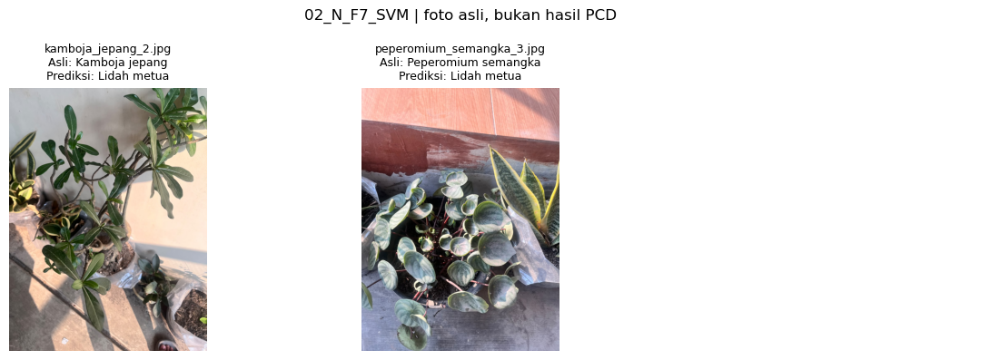


Peringkat 3: ('N', 'F8', 'SVM') | 60 foto OOF


,precision,recall,f1-score,support
Aglaonema,1.000000,1.000000,1.000000,10.000000
Daun nangka,1.000000,1.000000,1.000000,9.000000
Kamboja jepang,1.000000,0.888889,0.941176,9.000000
Lidah metua,0.857143,1.000000,0.923077,12.000000
Paku tanduk rusa,1.000000,1.000000,1.000000,14.000000
Peperomium semangka,1.000000,0.833333,0.909091,6.000000
accuracy,0.966667,0.966667,0.966667,0.966667
macro avg,0.976190,0.953704,0.962224,60.000000
weighted avg,0.971429,0.966667,0.966701,60.000000


,kelas,support,jumlah_salah,error_rate
5,Peperomium semangka,6,1,0.166667
2,Kamboja jepang,9,1,0.111111
1,Daun nangka,9,0,0.000000
0,Aglaonema,10,0,0.000000
3,Lidah metua,12,0,0.000000
4,Paku tanduk rusa,14,0,0.000000


,fold,profile,accuracy,macro_f1,params
16,0,2,1.000000,1.000000,"{""C"": 1, ""gamma"": ""scale""}"
124,1,2,0.833333,0.722222,"{""C"": 1, ""gamma"": ""scale""}"
232,2,2,1.000000,1.000000,"{""C"": 1, ""gamma"": ""scale""}"
340,3,2,1.000000,1.000000,"{""C"": 1, ""gamma"": ""scale""}"
448,4,2,1.000000,1.000000,"{""C"": 1, ""gamma"": ""scale""}"


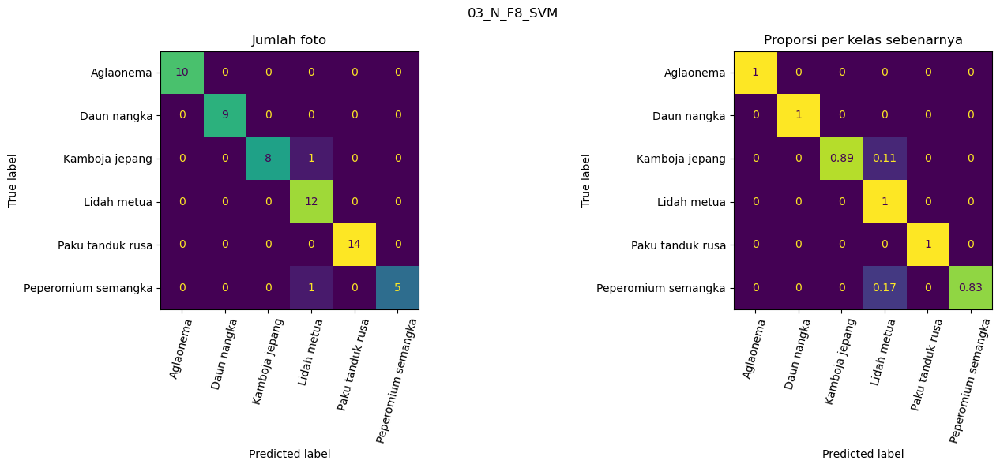

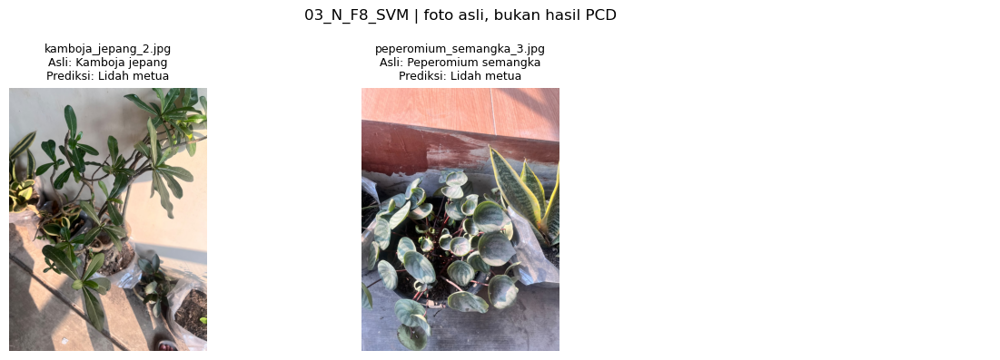


Peringkat 4: ('N', 'F5', 'SVM') | 60 foto OOF


,precision,recall,f1-score,support
Aglaonema,0.909091,1.000000,0.952381,10.000000
Daun nangka,0.875000,0.777778,0.823529,9.000000
Kamboja jepang,0.888889,0.888889,0.888889,9.000000
Lidah metua,1.000000,1.000000,1.000000,12.000000
Paku tanduk rusa,1.000000,0.928571,0.962963,14.000000
Peperomium semangka,0.857143,1.000000,0.923077,6.000000
accuracy,0.933333,0.933333,0.933333,0.933333
macro avg,0.921687,0.932540,0.925140,60.000000
weighted avg,0.935146,0.933333,0.932592,60.000000


,kelas,support,jumlah_salah,error_rate
1,Daun nangka,9,2,0.222222
2,Kamboja jepang,9,1,0.111111
4,Paku tanduk rusa,14,1,0.071429
0,Aglaonema,10,0,0.000000
3,Lidah metua,12,0,0.000000
5,Peperomium semangka,6,0,0.000000


,fold,profile,accuracy,macro_f1,params
10,0,2,1.000000,1.000000,"{""C"": 10, ""gamma"": 0.01}"
118,1,2,0.833333,0.827778,"{""C"": 10, ""gamma"": 0.01}"
226,2,2,0.916667,0.888889,"{""C"": 1, ""gamma"": ""scale""}"
334,3,2,0.916667,0.933333,"{""C"": 1, ""gamma"": 0.01}"
442,4,2,1.000000,1.000000,"{""C"": 1, ""gamma"": ""scale""}"


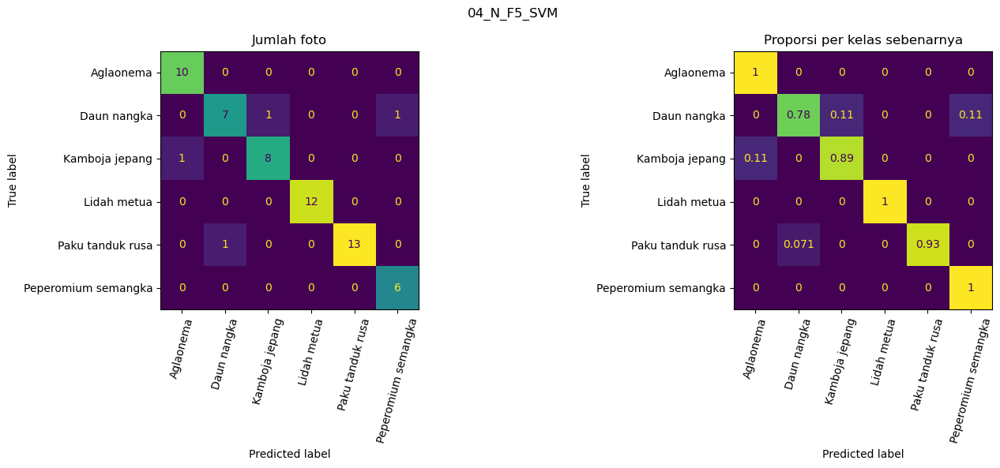

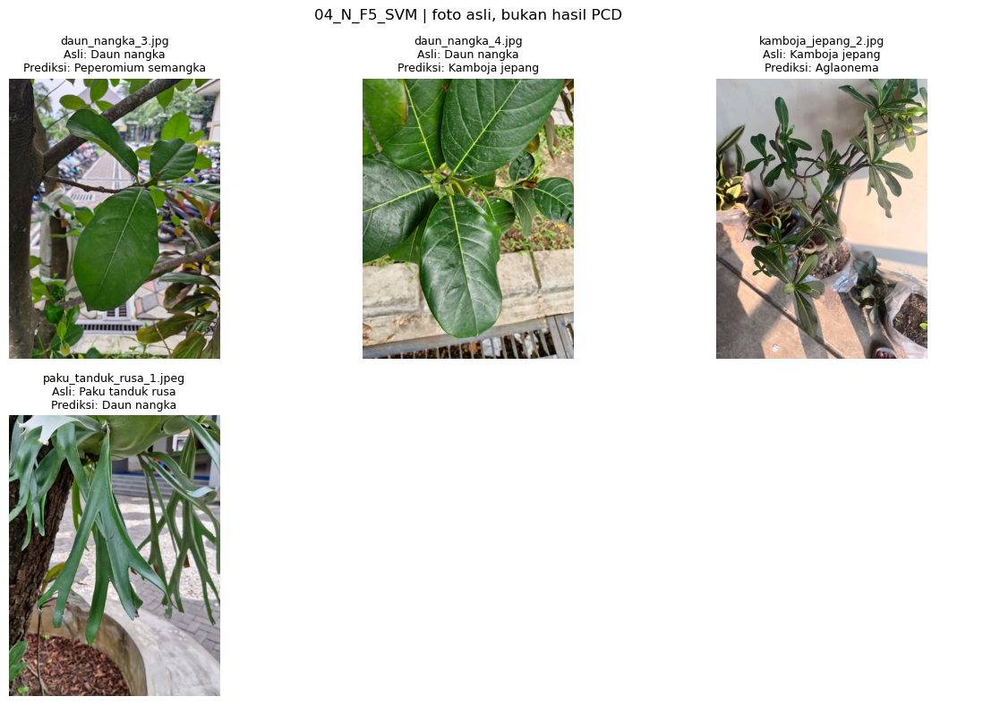

Ringkasan empat konfigurasi:


,input,feature,model,macro_f1_mean,macro_f1_std,macro_f1_pooled_oof,jumlah_salah,jumlah_foto
0,N,F4,SVM,0.944444,0.124226,0.962224,2,60
1,N,F7,SVM,0.944444,0.124226,0.962224,2,60
2,N,F8,SVM,0.944444,0.124226,0.962224,2,60
3,N,F5,SVM,0.930000,0.074079,0.925140,4,60


Foto yang salah pada setidaknya satu konfigurasi:


,image,true,01_N_F4_SVM_pred,01_N_F4_SVM_correct,02_N_F7_SVM_pred,02_N_F7_SVM_correct,03_N_F8_SVM_pred,03_N_F8_SVM_correct,04_N_F5_SVM_pred,04_N_F5_SVM_correct,jumlah_konfigurasi_salah
20,kamboja_jepang_2.jpg,Kamboja jepang,Lidah metua,False,Lidah metua,False,Lidah metua,False,Aglaonema,False,4
56,peperomium_semangka_3.jpg,Peperomium semangka,Lidah metua,False,Lidah metua,False,Lidah metua,False,Peperomium semangka,True,3
12,daun_nangka_3.jpg,Daun nangka,Daun nangka,True,Daun nangka,True,Daun nangka,True,Peperomium semangka,False,1
13,daun_nangka_4.jpg,Daun nangka,Daun nangka,True,Daun nangka,True,Daun nangka,True,Kamboja jepang,False,1
40,paku_tanduk_rusa_1.jpeg,Paku tanduk rusa,Paku tanduk rusa,True,Paku tanduk rusa,True,Paku tanduk rusa,True,Daun nangka,False,1


Hasil tersimpan: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_top4
Analisis deskriptif pada hasil OOF yang sudah ada; tidak ada training ulang atau tuning tambahan.


In [11]:
# Mandiri: jalankan cell ini saja setelah hasil benchmark tersedia; tidak ada fit/training.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score

if globals().get('USE_GITHUB_ARTIFACTS',False):
    EA_ROOT = ROOT
    EA_RESULTS = GITHUB_RESULTS
else:
    EA_FOLDER = Path(globals().get('OUT',Path('hasil_ml_full_aug'))).name
    EA_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p/'ablasi ML awal'/EA_FOLDER/'oof_predictions.csv').is_file()),None)
    assert EA_ROOT is not None, 'Hasil OOF belum ditemukan. Periksa lokasi hasil benchmark.'
    EA_RESULTS = EA_ROOT/'ablasi ML awal'/EA_FOLDER
EA_OUT = Path(OUT)/'error_analysis_top4'
EA_OUT.mkdir(parents=True, exist_ok=True)
ea_summary = github_read_csv('summary_108.csv') if globals().get('USE_GITHUB_ARTIFACTS',False) else pd.read_csv(EA_RESULTS/'summary_108.csv')
ea_pred = github_read_csv('oof_predictions.csv') if globals().get('USE_GITHUB_ARTIFACTS',False) else pd.read_csv(EA_RESULTS/'oof_predictions.csv')
ea_metrics = github_read_csv('metrics_per_fold.csv') if globals().get('USE_GITHUB_ARTIFACTS',False) else pd.read_csv(EA_RESULTS/'metrics_per_fold.csv')
ea_pred['correct'] = ea_pred['true'].eq(ea_pred['pred'])
ea_labels = sorted(ea_pred['true'].unique())
# Ikuti empat baris teratas pada summary yang tersimpan, termasuk urutan tie-nya.
ea_top = ea_summary.head(4).copy()
assert len(ea_top) == 4, 'Diperlukan setidaknya empat konfigurasi.'
display(ea_top)
ea_class_tables, ea_fold_tables, ea_overview = [], [], []
ea_comparison = None

for ea_rank, ea_row in enumerate(ea_top.itertuples(index=False), start=1):
    ea_key = (ea_row.input, ea_row.feature, ea_row.model)
    ea_tag = f'{ea_rank:02d}_{ea_row.input}_{ea_row.feature}_{ea_row.model}'
    ea_dir = EA_OUT/ea_tag
    ea_dir.mkdir(exist_ok=True)
    ea_d = ea_pred.loc[(ea_pred['input']==ea_key[0]) &
                       (ea_pred['feature']==ea_key[1]) & (ea_pred['model']==ea_key[2])].copy()
    assert len(ea_d) and not ea_d['image'].duplicated().any(), 'OOF harus satu prediksi per foto.'
    print(f'\nPeringkat {ea_rank}: {ea_key} | {len(ea_d)} foto OOF')
    ea_report = pd.DataFrame(classification_report(
        ea_d['true'], ea_d['pred'], labels=ea_labels,
        output_dict=True, zero_division=0)).T
    ea_report.to_csv(ea_dir/'classification_report.csv')
    display(ea_report)
    ea_class = pd.DataFrame([
        dict(kelas=ea_label, support=int((ea_d['true']==ea_label).sum()),
             jumlah_salah=int(((ea_d['true']==ea_label)&~ea_d['correct']).sum()))
        for ea_label in ea_labels])
    ea_class['error_rate'] = ea_class['jumlah_salah']/ea_class['support'].replace(0,np.nan)
    ea_class.to_csv(ea_dir/'class_errors.csv',index=False)
    ea_class_tables.append(ea_class.assign(input=ea_key[0],feature=ea_key[1],model=ea_key[2]))
    display(ea_class.sort_values('jumlah_salah',ascending=False))
    ea_folds = ea_metrics.loc[(ea_metrics['input']==ea_key[0]) &
                             (ea_metrics['feature']==ea_key[1]) & (ea_metrics['model']==ea_key[2])]
    ea_folds.to_csv(ea_dir/'metrics_per_fold.csv',index=False)
    ea_fold_tables.append(ea_folds)
    display(ea_folds[['fold','profile','accuracy','macro_f1','params']])
    ea_overview.append(dict(input=ea_key[0],feature=ea_key[1],model=ea_key[2],
        macro_f1_mean=ea_row.macro_f1_mean,macro_f1_std=ea_row.macro_f1_std,
        macro_f1_pooled_oof=f1_score(ea_d['true'],ea_d['pred'],labels=ea_labels,
                                    average='macro',zero_division=0),
        jumlah_salah=int((~ea_d['correct']).sum()),jumlah_foto=len(ea_d)))
    ea_fig, ea_axes = plt.subplots(1,2,figsize=(15,6))
    for ea_ax,ea_norm in zip(ea_axes,(None,'true')):
        ConfusionMatrixDisplay.from_predictions(ea_d['true'],ea_d['pred'],labels=ea_labels,
            normalize=ea_norm,ax=ea_ax,xticks_rotation=75,colorbar=False)
        ea_ax.set_title('Jumlah foto' if ea_norm is None else 'Proporsi per kelas sebenarnya')
    ea_fig.suptitle(ea_tag)
    ea_fig.tight_layout()
    ea_fig.savefig(ea_dir/'confusion_matrix.png',dpi=140,bbox_inches='tight')
    plt.show(); plt.close(ea_fig)
    ea_wrong = ea_d.loc[~ea_d['correct']].sort_values(['true','image'])
    ea_wrong.to_csv(ea_dir/'wrong_predictions.csv',index=False)
    ea_pairs = ea_wrong.groupby(['true','pred']).size().rename('jumlah').reset_index()
    ea_pairs.sort_values('jumlah',ascending=False).to_csv(ea_dir/'confusion_pairs.csv',index=False)
    if len(ea_wrong):
        # Foto asli sebagai contoh kesalahan; tidak menghitung ulang PCD atau fitur.
        ea_n = min(12,len(ea_wrong))
        ea_fig,ea_axes = plt.subplots(int(np.ceil(ea_n/3)),3,
            figsize=(12,4*int(np.ceil(ea_n/3))),squeeze=False)
        for ea_ax in ea_axes.flat: ea_ax.axis('off')
        for ea_ax,ea_item in zip(ea_axes.flat,ea_wrong.head(ea_n).itertuples(index=False)):
            ea_path = EA_ROOT/'Dataset'/str(ea_item.true)/str(ea_item.image)
            if ea_path.is_file():
                with Image.open(ea_path) as ea_im:
                    ea_ax.imshow(ImageOps.exif_transpose(ea_im).convert('RGB'))
            else:
                ea_ax.text(.5,.5,'Foto tidak ditemukan',ha='center')
            ea_ax.set_title(f'{ea_item.image}\nAsli: {ea_item.true}\nPrediksi: {ea_item.pred}',fontsize=9)
        ea_fig.suptitle(ea_tag+' | foto asli, bukan hasil PCD')
        ea_fig.tight_layout()
        ea_fig.savefig(ea_dir/'wrong_examples_original.png',dpi=130,bbox_inches='tight')
        plt.show(); plt.close(ea_fig)
    else:
        print('Tidak ada kesalahan OOF pada konfigurasi ini.')
    ea_piece = ea_d[['image','true','pred','correct']].rename(
        columns={'pred':ea_tag+'_pred','correct':ea_tag+'_correct'})
    ea_comparison = ea_piece if ea_comparison is None else ea_comparison.merge(
        ea_piece,on=['image','true'],how='outer',validate='one_to_one')

ea_correct_cols = [ea_col for ea_col in ea_comparison if ea_col.endswith('_correct')]
assert ea_comparison[ea_correct_cols].notna().all().all(), 'Foto OOF antarkonfigurasi tidak sama.'
ea_comparison['jumlah_konfigurasi_salah'] = (~ea_comparison[ea_correct_cols].astype(bool)).sum(axis=1)
ea_comparison = ea_comparison.sort_values(['jumlah_konfigurasi_salah','image'],ascending=[False,True])
ea_comparison.to_csv(EA_OUT/'perbandingan_prediksi_per_foto.csv',index=False)
pd.concat(ea_class_tables,ignore_index=True).to_csv(EA_OUT/'class_errors_top4.csv',index=False)
pd.concat(ea_fold_tables,ignore_index=True).to_csv(EA_OUT/'metrics_per_fold_top4.csv',index=False)
ea_overview = pd.DataFrame(ea_overview)
ea_overview.to_csv(EA_OUT/'ringkasan_top4.csv',index=False)
print('Ringkasan empat konfigurasi:')
display(ea_overview)
print('Foto yang salah pada setidaknya satu konfigurasi:')
display(ea_comparison.loc[ea_comparison['jumlah_konfigurasi_salah']>0])
print('Hasil tersimpan:',EA_OUT)
print('Analisis deskriptif pada hasil OOF yang sudah ada; tidak ada training ulang atau tuning tambahan.')


## 8. Feature importance pada data outer-evaluation

Permutation importance memakai **penurunan macro-F1** saat satu fitur diacak pada foto outer-evaluation, terpisah dari fitting. Disediakan untuk SVM dan RF pada paket/input analisis. Nilai negatif boleh terjadi; fitur berkorelasi dapat saling menggantikan sehingga importance bukan kausalitas. Tambahkan pengacakan **blok** warna/Sobel/Canny/BoVW untuk menguji kontribusi kelompok.

Word BoVW dan profil/dimensi dapat berbeda antar fold: importance individual ditampilkan per fold dan tidak merata-ratakan word indeks lintas kamus. Importance blok boleh diringkas antarfold. Untuk RF, impurity importance disimpan sebagai tambahan dengan bias terhadap fitur kontinu; interpretasi utama memakai permutation OOF. Foto evaluasi dipakai untuk penjelasan deskriptif ini, tidak untuk melatih ulang atau mengganti parameter.

Dalam mode artefak, nilai importance langsung dibaca dari CSV GitHub. Model lama tidak direkonstruksi atau di-fit ulang.


mean       std
model block                    
RF    bovw   0.115667  0.095394
      color  0.668952  0.086346
SVM   bovw   0.422563  0.133508
      color  0.552471  0.074995

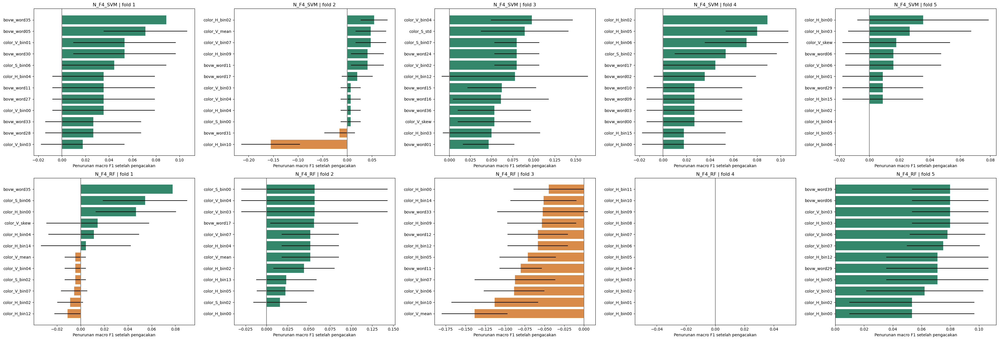

,no_sift,empty_edge
input,,
E,0.000000,0.0
E-S-K,0.150000,0.0
E-S-O,0.016667,0.0
N,0.000000,0.0
S-K,0.133333,0.0
S-O,0.050000,0.0


Lulus pemeriksaan: 540 baris fold, 6480 prediksi OOF; output: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap
Hasil eksploratif; validasi tanaman independen bergantung plant_id dan QC.


In [12]:
if USE_GITHUB_ARTIFACTS:
    imp_df=github_read_csv('permutation_importance_by_fold.csv')
    block_df=github_read_csv('block_importance.csv')
    mdi_df=github_read_csv('rf_impurity_importance_by_fold.csv')
    if set(imp_df.input)!={c} or set(imp_df.feature)!={f}:
        raise ValueError('Konfigurasi feature importance tersimpan berbeda dari konfigurasi analisis.')
    print('Feature importance asli dibaca dari GitHub, tanpa menghitung ulang permutation importance.')
else:
    importance_rows, block_rows, mdi_rows = [],[],[]
    for model in ('SVM','RF'):
        for fold,(tr,te) in enumerate(outer):
            est,pid=fitted[(fold,c,f,model)]
            X=matrix(c,pid,tr,f); feature_names=names(pid,f)
            imp=permutation_importance(est,X[te],y[te],scoring='f1_macro',n_repeats=PERM_REPEATS,random_state=SEED,n_jobs=1)
            for n,mean,std in zip(feature_names,imp.importances_mean,imp.importances_std):
                importance_rows.append(dict(model=model,fold=fold,input=c,feature=f,name=n,mean=mean,std=std,profile=pid))
            base=f1_score(y[te],est.predict(X[te]),labels=LABELS,average='macro',zero_division=0)
            rng=np.random.default_rng(SEED)
            for block in PACKAGES[f]:
                cols=[j for j,n in enumerate(feature_names) if n.startswith(block+'_')]
                drops=[]
                for repeat in range(PERM_REPEATS):
                    xp=X[te].copy(); order=rng.permutation(len(te))
                    xp[:,cols]=xp[order][:,cols]
                    drops.append(base-f1_score(y[te],est.predict(xp),labels=LABELS,average='macro',zero_division=0))
                block_rows.append(dict(model=model,fold=fold,block=block,mean=np.mean(drops),std=np.std(drops)))
            if model=='RF':
                mdi_rows.extend(dict(fold=fold,name=n,importance=v) for n,v in zip(feature_names,est[-1].feature_importances_))
    imp_df=pd.DataFrame(importance_rows); imp_df.to_csv(OUT/'permutation_importance_by_fold.csv',index=False)
    block_df=pd.DataFrame(block_rows); block_df.to_csv(OUT/'block_importance.csv',index=False)
    pd.DataFrame(mdi_rows).to_csv(OUT/'rf_impurity_importance_by_fold.csv',index=False)
display(block_df.groupby(['model','block'])['mean'].agg(['mean','std']))
fig,axes=plt.subplots(2,len(outer),figsize=(7*len(outer),12),squeeze=False)
for row,model in enumerate(('SVM','RF')):
    for fold in range(len(outer)):
        # Konsisten dengan 8b: besar perubahan absolut, tanda asli tetap dipertahankan.
        top=(imp_df[imp_df.model.eq(model)&imp_df.fold.eq(fold)]
             .assign(abs_mean=lambda d:d['mean'].abs())
             .nlargest(12,'abs_mean').sort_values('mean'))
        axes[row,fold].barh(top['name'],top['mean'],xerr=top['std'],
            color=np.where(top['mean']<0,'#D98C4A','#34876A'))
        axes[row,fold].axvline(0,color='gray')
        axes[row,fold].set_title(f'{c}_{f}_{model} | fold {fold+1}')
        axes[row,fold].set_xlabel('Penurunan macro F1 setelah pengacakan')
plt.tight_layout(); plt.show()
if USE_GITHUB_ARTIFACTS:
    raw_audit=github_read_csv('feature_qc_profile0.csv')
else:
    raw_audit = pd.DataFrame([dict(image=meta.iloc[i].image,input=ci,n_sift=len(raw_features(i,ci,0)['desc']),
        edge_domain_empty=bool(np.isnan(raw_features(i,ci,0)['sobel']).all())) for ci in CONDITIONS for i in range(len(meta))])
raw_audit.to_csv(OUT/'feature_qc_profile0.csv',index=False)
display(raw_audit.groupby('input').agg(no_sift=('n_sift',lambda s:float(s.eq(0).mean())),empty_edge=('edge_domain_empty','mean')))
print('Lulus pemeriksaan:',len(score_df),'baris fold,',len(pred_df),'prediksi OOF; output:',OUT)
print('SMOKE TEST saja. Ubah SMOKE_TEST=False dan gunakan kernel ai_env untuk full training.' if SMOKE_TEST else 'Hasil eksploratif; validasi tanaman independen bergantung plant_id dan QC.')

### 8b. Feature importance skor tertinggi selain F4




Konfigurasi seri pada skor tertinggi, selain F4:


,input,feature,model,macro_f1_mean,macro_f1_std,accuracy_mean,total_s
1,N,F7,SVM,0.944444,0.124226,0.966667,0.179812
2,N,F8,SVM,0.944444,0.124226,0.966667,0.182862


Analisis: N_F7_SVM


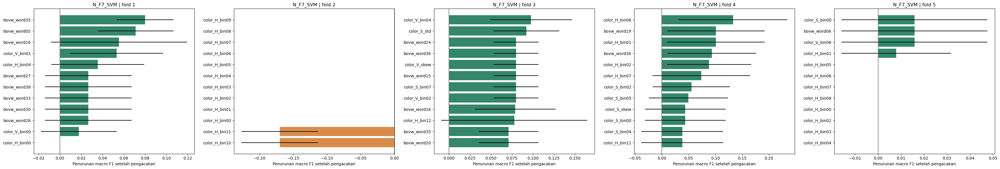

Analisis: N_F8_SVM


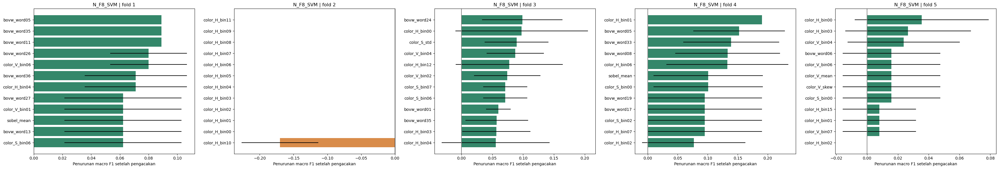

,input,feature,model,block,importance_mean,importance_std_across_folds
0,N,F7,SVM,bovw,0.319651,0.146162
1,N,F7,SVM,canny,0.054690,0.040242
2,N,F7,SVM,color,0.484540,0.095240
3,N,F8,SVM,bovw,0.317524,0.146109
4,N,F8,SVM,color,0.483071,0.094512
5,N,F8,SVM,sobel,0.073897,0.054477


Hasil: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\feature_importance_best_non_f4


In [13]:
if USE_GITHUB_ARTIFACTS:
    fi_targets=github_read_csv('feature_importance_best_non_f4/selected_configurations.csv')
    fi_all=github_read_csv('feature_importance_best_non_f4/permutation_importance_by_fold.csv')
    fi_blocks_df=github_read_csv('feature_importance_best_non_f4/block_importance_by_fold.csv')
    fi_block_summary=github_read_csv('feature_importance_best_non_f4/block_importance_summary.csv')
    display(fi_targets,fi_block_summary)
    for fi_row in fi_targets.itertuples(index=False):
        fi_fig,fi_axes=plt.subplots(1,len(outer),figsize=(7*len(outer),6),squeeze=False)
        for fi_fold in range(len(outer)):
            fi_table=fi_all[fi_all.input.eq(fi_row.input)&fi_all.feature.eq(fi_row.feature)&fi_all.model.eq(fi_row.model)&fi_all.fold.eq(fi_fold)]
            fi_top=fi_table.assign(abs_mean=fi_table['mean'].abs()).nlargest(12,'abs_mean').sort_values('mean')
            ax=fi_axes[0,fi_fold]
            ax.barh(fi_top['name'],fi_top['mean'],xerr=fi_top['std'],color=np.where(fi_top['mean']<0,'#D98C4A','#34876A'))
            ax.axvline(0,color='gray')
            ax.set_title(f'{fi_row.input}_{fi_row.feature}_{fi_row.model} | fold {fi_fold+1}')
            ax.set_xlabel('Penurunan macro F1 setelah pengacakan')
        fi_fig.tight_layout()
        plt.show()
        plt.close(fi_fig)
    print('8b: seluruh nilai importance berasal dari GitHub, tanpa model baru.')
else:
    # 8b - Feature importance tertinggi selain F4. Semua kode ada di cell ini.
    """Permutation importance konfigurasi skor tertinggi selain F4; tanpa refit."""
    from pathlib import Path
    import sys
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from IPython.display import display
    from sklearn.inspection import permutation_importance
    from sklearn.metrics import f1_score

    fi_missing = [k for k in ('fitted','outer','matrix','names','PACKAGES','y','LABELS','OUT','SEED','encode') if k not in globals()]
    if fi_missing:
        raise RuntimeError('Gunakan kernel training yang masih aktif. Objek tidak tersedia: '+', '.join(fi_missing)+'. Tidak melakukan training ulang.')
    fi_summary = pd.read_csv(Path(OUT)/'summary_108.csv')
    fi_targets = fi_summary.loc[np.isclose(fi_summary.macro_f1_mean,fi_summary.macro_f1_mean.max(),rtol=0,atol=1e-12) & fi_summary.feature.ne('F4')].copy()
    print('Konfigurasi seri pada skor tertinggi, selain F4:')
    display(fi_targets)
    fi_destination = Path(OUT)/'feature_importance_best_non_f4'
    fi_destination.mkdir(exist_ok=True)
    fi_records, fi_block_records = [], []
    def fi_scoring(estimator, X_eval, y_eval):
        # Callable langsung: tidak membawa default pos_label=1 dari make_scorer.
        return f1_score(y_eval, estimator.predict(X_eval), labels=LABELS,
                        average='macro', zero_division=0)
    fi_repeats = int(globals().get('PERM_REPEATS',10))

    def fi_cached_matrix(condition,profile,train,package):
        # Cache miss akan masuk ke body encode; hentikan sebelum kamus BoVW dilatih.
        original_code = encode.__wrapped__.__code__
        previous_profile = sys.getprofile()
        def guard(frame,event,arg):
            if event == 'call' and frame.f_code is original_code:
                raise RuntimeError('Cache fitur/BoVW untuk konfigurasi ini tidak tersedia. Berhenti tanpa training ulang.')
        try:
            sys.setprofile(guard)
            return matrix(condition,profile,train,package)
        finally:
            sys.setprofile(previous_profile)

    for fi_row in fi_targets.itertuples(index=False):
        fi_tag = f'{fi_row.input}_{fi_row.feature}_{fi_row.model}'
        print('Analisis:',fi_tag,flush=True)
        fi_fig, fi_axes = plt.subplots(1,len(outer),figsize=(7*len(outer),6),squeeze=False)
        for fi_fold,(fi_train,fi_test) in enumerate(outer):
            fi_key = (fi_fold,fi_row.input,fi_row.feature,fi_row.model)
            if fi_key not in fitted:
                raise RuntimeError(f'Model tidak tersedia: {fi_key}. Tidak melakukan training ulang.')
            fi_est,fi_pid = fitted[fi_key]
            fi_X = fi_cached_matrix(fi_row.input,fi_pid,fi_train,fi_row.feature)
            fi_names = names(fi_pid,fi_row.feature)
            fi_result = permutation_importance(fi_est,fi_X[fi_test],y[fi_test],scoring=fi_scoring,
                n_repeats=fi_repeats,random_state=SEED,n_jobs=1)
            fi_table = pd.DataFrame({'name':fi_names,'mean':fi_result.importances_mean,'std':fi_result.importances_std})
            fi_table = fi_table.assign(input=fi_row.input,feature=fi_row.feature,model=fi_row.model,fold=fi_fold,profile=fi_pid)
            fi_records.append(fi_table)
            # Pilih perubahan terbesar berdasarkan absolut, tetapi pertahankan tanda asli.
            fi_top = fi_table.assign(abs_mean=fi_table['mean'].abs()).nlargest(12,'abs_mean').sort_values('mean')
            fi_axis = fi_axes[0,fi_fold]
            fi_axis.barh(fi_top['name'],fi_top['mean'],xerr=fi_top['std'],
                color=np.where(fi_top['mean']<0,'#D98C4A','#34876A'))
            fi_axis.axvline(0,color='gray')
            fi_axis.set_title(f'{fi_tag} | fold {fi_fold+1}')
            fi_axis.set_xlabel('Penurunan macro F1 setelah pengacakan')
            fi_base = f1_score(y[fi_test],fi_est.predict(fi_X[fi_test]),labels=LABELS,average='macro',zero_division=0)
            fi_rng = np.random.default_rng(SEED)
            for fi_block in PACKAGES[fi_row.feature]:
                fi_cols = [j for j,name in enumerate(fi_names) if name.startswith(fi_block+'_')]
                assert fi_cols,fi_block
                fi_drops=[]
                for fi_repeat in range(fi_repeats):
                    fi_permuted = fi_X[fi_test].copy()
                    fi_order = fi_rng.permutation(len(fi_test))
                    fi_permuted[:,fi_cols] = fi_permuted[fi_order][:,fi_cols]
                    fi_drops.append(fi_base-f1_score(y[fi_test],fi_est.predict(fi_permuted),labels=LABELS,average='macro',zero_division=0))
                fi_block_records.append(dict(input=fi_row.input,feature=fi_row.feature,model=fi_row.model,
                    fold=fi_fold,profile=fi_pid,block=fi_block,mean=float(np.mean(fi_drops)),std=float(np.std(fi_drops))))
        fi_fig.tight_layout()
        fi_fig.savefig(fi_destination/(fi_tag+'_importance_by_fold.png'),dpi=140,bbox_inches='tight')
        plt.show(); plt.close(fi_fig)
    if fi_records:
        pd.concat(fi_records,ignore_index=True).to_csv(fi_destination/'permutation_importance_by_fold.csv',index=False)
        fi_blocks_df = pd.DataFrame(fi_block_records)
        fi_blocks_df.to_csv(fi_destination/'block_importance_by_fold.csv',index=False)
        fi_block_summary = fi_blocks_df.groupby(['input','feature','model','block']).agg(
            importance_mean=('mean','mean'),importance_std_across_folds=('mean','std')).reset_index()
        fi_block_summary.to_csv(fi_destination/'block_importance_summary.csv',index=False)
        fi_targets.to_csv(fi_destination/'selected_configurations.csv',index=False)
        display(fi_block_summary)
        print('Hasil:',fi_destination)
    else:
        print('Tidak ada konfigurasi tertinggi selain F4.')


---
# BAGIAN TAMBAHAN ? Error analysis dari run yang dipilih

Sumber prediksi/profil/QC mengikuti mode notebook. Jika `USE_GITHUB_ARTIFACTS=True`, sumbernya snapshot GitHub. Jika `REPRODUCE_GITHUB_RUN=True`, sumbernya hasil training baru pada `OUT`. Analisis tidak mengganti prediksi training baru dengan hasil lama.

| Bagian | Kegiatan |
|---|---|
| 9&10 | Memuat sumber run dan menganalisis perubahan prediksi antar kondisi |
| 11&12 | Menghitung diagnosis fitur/mask dari foto dengan urutan dan hash yang sama |
| 13 | Analisis separabilitas dengan vocabulary bersama, opsional |
| 14&15 | Eksperimen kontrol background/vocabulary/transfer, opsional |
| 16 | Laporan dengan asal prediksi dan mode eksekusi |

Bagian 13?15 hanya aktif jika `RUN_NEW_DIAGNOSTIC_MODELS=True` karena merupakan diagnosis tersendiri. Pada mode baca, kamus BoVW asli tidak tersedia sehingga perlu direkonstruksi jika ingin menjalankan bagian tersebut. Pada mode reproduksi, kamus/model benchmark berasal dari training baru. Skor kontrol berparameter tetap tanpa augmentasi tidak menggantikan skor benchmark nested CV.

Tidak ada ground truth mask atau identitas individu tanaman dalam artefak awal. Diagnosis bersifat eksploratif.


## 9. Setup, pemilihan skenario, dan helper ekspor

Perbandingan utama mempertahankan `F4 = color + BoVW` dengan SVM. Profil fitur tetap untuk audit deskriptif (`EA_FIXED_PID=0`). Untuk evaluasi per fold, gunakan **profil yang dipilih oleh nested CV dari training** pada fold tersebut; tak ada informasi dari outer-test yang digunakan untuk memilih profil.

Jika ingin mengukur **IoU/Dice mask**, sediakan gambar biner secara manual pada `Dataset/leaf_masks/<nama_file_tanpa_ekstensi>.png` (255 = daun, 0 = latar); folder tersebut bersifat opsional. Pilih anotasi pada citra asli dengan orientasi yang sama. Kode hanya menghitung metrik untuk gambar yang memang dianotasi.

In [14]:
from functools import lru_cache
from scipy.stats import binomtest, spearmanr
from scipy.spatial.distance import cdist, jensenshannon
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

EA_ARTIFACTS = GITHUB_RESULTS if USE_GITHUB_ARTIFACTS else OUT
EA_DIR = Path(OUT) / 'error_analysis_tambahan'
EA_DIR.mkdir(parents=True, exist_ok=True)
EA_REFERENCE = 'N'
EA_CONDS = list(CONDITIONS)
EA_FOCUS_FEATURE = 'F4'
EA_FOCUS_MODEL = 'SVM'
EA_FIXED_PID = 0
EA_PLOT_FOLD = 0  # Plot PCA dari fold terpilih (proyeksi fit hanya pada N-train).
EA_MAX_EXAMPLES = 6
EA_MASK_AUTO = 'S-K'  # Hanya PROXY foreground; tidak otomatis benar secara botani.
EA_GT_MASK_DIR = ROOT/'Dataset'/'leaf_masks'
EA_IDX = {str(r.image):i for i,r in meta.reset_index(drop=True).iterrows()}
ea_profile_path = github_file('selected_profiles.json') if USE_GITHUB_ARTIFACTS else OUT/'selected_profiles.json'
ea_selected_profiles = json.loads(ea_profile_path.read_text(encoding='utf-8'))
EA_FOLD_PID = {int(r['fold']):int(r['profile']) for r in ea_selected_profiles}
assert len(EA_IDX)==len(meta), 'Nama foto harus unik.'
assert EA_FOCUS_FEATURE == 'F4' and EA_FOCUS_MODEL == 'SVM'
assert 0 <= EA_PLOT_FOLD < len(outer)
assert all(EA_FOLD_PID[f] < len(PROFILES) for f in range(len(outer)))

# Baca ulang agar blok ini dapat dieksekusi lagi tanpa mengandalkan pred_df aktif.
ea_preds = analysis_read_csv('oof_predictions.csv')
ea_preds = ea_preds.query('feature == @EA_FOCUS_FEATURE and model == @EA_FOCUS_MODEL').copy()
assert ea_preds.groupby(['input','image']).size().eq(1).all()
assert set(ea_preds.input)==set(EA_CONDS)
assert ea_preds.groupby('input').size().eq(len(meta)).all()
assert ea_preds.groupby('image').true.nunique().eq(1).all()

def ea_savefig(fig, filename):
    p=EA_DIR/filename
    fig.savefig(p,dpi=150,bbox_inches='tight',facecolor='white')
    plt.show(); plt.close(fig)
    print('Plot:',p)

def ea_csv(table, filename):
    p=EA_DIR/filename
    table.to_csv(p,index=False)
    print('CSV:',p)
    return table

print('Output:', EA_DIR)
print('Skenario:',EA_CONDS,'| outer-fold:',len(outer),'| profil deskriptif:',EA_FIXED_PID)
print('Anotasi manual (opsional):',EA_GT_MASK_DIR)
ea_sep=ea_neighbors=ea_pairs=None
EA_BG_MASK_MODE='not_run'
print('Prediksi yang dianalisis:',EA_ARTIFACTS)
print('Model diagnostik baru aktif:',RUN_NEW_DIAGNOSTIC_MODELS)


Output: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan
Skenario: ['N', 'E', 'S-O', 'S-K', 'E-S-O', 'E-S-K'] | outer-fold: 5 | profil deskriptif: 0
Anotasi manual (opsional): e:\PCD\Project Akhir\Dataset\leaf_masks
Prediksi yang dianalisis: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap
Model diagnostik baru aktif: True


## 10. Prediction transition — perubahan prediksi per foto

Bandingkan **foto dan fold yang sama** antara `N` dan semua varian PCD, khusus SVM–F4. Hitung jumlah `benar → salah` (*loss*) dan `salah → benar` (*gain*), confusion per kelas, serta uji **McNemar eksak (binomial dua sisi)** dengan unit pasangan foto. Nilai *p* hanya eksploratif: hasil model dipilih dari beberapa eksperimen dan foto/individu tanaman belum independen secara pasti.

CSV: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\01_prediction_transition_per_image.csv
CSV: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\01_prediction_transition_summary.csv
CSV: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\01_prediction_transition_by_class.csv


,condition,n,accuracy,original_accuracy,loss,gain,net_errors,discordant,mcnemar_exact_p
0,N,60,0.9667,0.9667,0,0,0,0,1.0000
1,E,60,0.9167,0.9667,3,0,3,3,0.2500
2,S-O,60,0.7500,0.9667,13,0,13,13,0.0002
3,S-K,60,0.8500,0.9667,7,0,7,7,0.0156
4,E-S-O,60,0.7833,0.9667,11,0,11,11,0.0010
5,E-S-K,60,0.8333,0.9667,8,0,8,8,0.0078


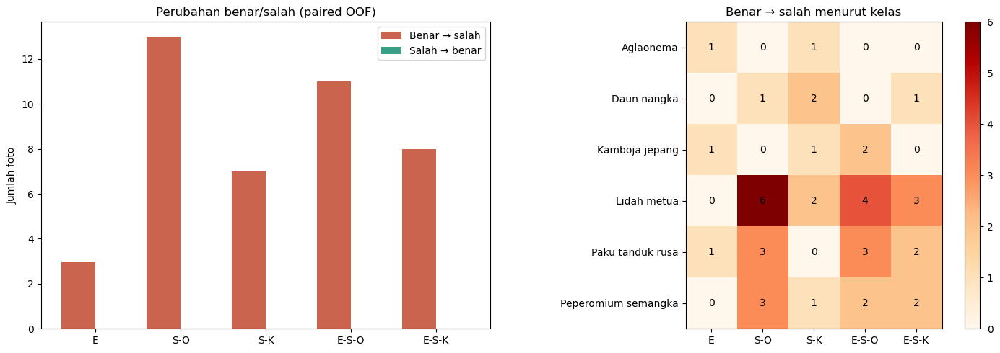

Plot: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\01_prediction_transition.png
Kasus dari benar → salah (top 20):


,condition,image,true,pred_N,pred_condition,mask_fraction
13,E,aglaonema_3.jpg,Aglaonema,Aglaonema,Daun nangka,1.000000
30,S-O,lidah_metua_2.jpg,Lidah metua,Lidah metua,Peperomium semangka,0.769837
31,S-O,lidah_metua_5.jpg,Lidah metua,Lidah metua,Peperomium semangka,0.845085
32,S-O,paku_tanduk_rusa_10.jpeg,Paku tanduk rusa,Paku tanduk rusa,Lidah metua,0.493747
34,S-O,paku_tanduk_rusa_8.jpeg,Paku tanduk rusa,Paku tanduk rusa,Lidah metua,0.574160
37,S-K,aglaonema_3.jpg,Aglaonema,Aglaonema,Daun nangka,1.000000
38,S-K,daun_nangka_1.jpg,Daun nangka,Daun nangka,Aglaonema,1.000000
42,S-K,lidah_metua_2.jpg,Lidah metua,Lidah metua,Peperomium semangka,0.221071
54,E-S-O,lidah_metua_2.jpg,Lidah metua,Lidah metua,Peperomium semangka,0.769414
55,E-S-O,lidah_metua_5.jpg,Lidah metua,Lidah metua,Peperomium semangka,0.850143


In [15]:
ea_base=(ea_preds.loc[ea_preds.input.eq('N'), ['image','fold','true','pred']]
         .rename(columns={'pred':'pred_N'}))
ea_transition=ea_preds.merge(ea_base,on=['image','fold','true'],how='left',validate='many_to_one')
assert ea_transition.pred_N.notna().all()
ea_transition['correct_N']=ea_transition.pred_N.eq(ea_transition.true)
ea_transition['correct_cond']=ea_transition.pred.eq(ea_transition.true)
ea_transition['transition']=np.select(
    [ea_transition.correct_N & ea_transition.correct_cond,
     ea_transition.correct_N & ~ea_transition.correct_cond,
     ~ea_transition.correct_N & ea_transition.correct_cond],
    ['tetap_benar','benar_ke_salah','salah_ke_benar'],default='tetap_salah')
ea_transition=ea_transition.rename(columns={'input':'condition','pred':'pred_condition'})
ea_saved_qc=analysis_read_csv('qc_pcd.csv').rename(columns={'input':'condition'})
ea_transition=ea_transition.merge(ea_saved_qc[['image','condition','mask_fraction']],on=['image','condition'],validate='one_to_one')
ea_csv(ea_transition,'01_prediction_transition_per_image.csv')

summary_rows=[]
for cond,d in ea_transition.groupby('condition',sort=False):
    lost=int(d.transition.eq('benar_ke_salah').sum())
    gain=int(d.transition.eq('salah_ke_benar').sum())
    discordant=lost+gain
    p=binomtest(min(lost,gain),discordant,p=.5,alternative='two-sided').pvalue if discordant else 1.
    summary_rows.append(dict(condition=cond,n=len(d),accuracy=float(d.correct_cond.mean()),
        original_accuracy=float(d.correct_N.mean()),loss=lost,gain=gain,
        net_errors=lost-gain,discordant=discordant,mcnemar_exact_p=p))
ea_transition_summary=ea_csv(pd.DataFrame(summary_rows),'01_prediction_transition_summary.csv')
ea_transition_class=ea_csv(
    ea_transition.groupby(['condition','true','transition']).size().rename('count').reset_index(),
    '01_prediction_transition_by_class.csv')
display(ea_transition_summary.round(4))
fig,axes=plt.subplots(1,2,figsize=(14,5))
d=ea_transition_summary[ea_transition_summary.condition.ne('N')]
xx=np.arange(len(d))
axes[0].bar(xx-.2,d.loss,width=.4,label='Benar → salah',color='#CB644E')
axes[0].bar(xx+.2,d.gain,width=.4,label='Salah → benar',color='#3B9F88')
axes[0].set_xticks(xx,d.condition);axes[0].set(ylabel='Jumlah foto',title='Perubahan benar/salah (paired OOF)')
axes[0].legend()
loss_grid=(ea_transition.loc[ea_transition.transition.eq('benar_ke_salah')]
    .groupby(['true','condition']).size().unstack('condition',fill_value=0)
    .reindex(index=LABELS,columns=[c for c in EA_CONDS if c!='N'],fill_value=0))
im=axes[1].imshow(loss_grid,cmap='OrRd',vmin=0)
axes[1].set_xticks(range(loss_grid.shape[1]),loss_grid.columns)
axes[1].set_yticks(range(len(LABELS)),LABELS)
for (rr,cc),v in np.ndenumerate(loss_grid.to_numpy()):axes[1].text(cc,rr,str(v),ha='center',va='center')
axes[1].set_title('Benar → salah menurut kelas');fig.colorbar(im,ax=axes[1],fraction=.05)
fig.tight_layout();ea_savefig(fig,'01_prediction_transition.png')
print('Kasus dari benar → salah (top 20):')
display(ea_transition.query("transition == 'benar_ke_salah'")
        [['condition','image','true','pred_N','pred_condition','mask_fraction']].head(20))

## 11. Feature Loss — jumlah SIFT, HSV, dan edge

Gunakan seluruh foto yang **sama** pada tiap kondisi, dengan profil fitur **tetap** agar dimensi fitur dan batas SIFT konsisten. Nilai `n_sift` adalah jumlah deskriptor **setelah filter daerah/batas dan cap 300** sesuai pipeline, bukan seluruh keypoint terdeteksi. `HSV JS distance` mengukur besarnya perubahan histogram, **bukan otomatis kehilangan informasi**. Besar perubahan ini akan dikaitkan dengan mask dan perubahan prediksi.

Jumlah SIFT profil 0 cocok dengan seluruh 360 baris QC sumber run.
CSV: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\02_feature_loss_per_image.csv
CSV: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\02_feature_loss_by_class.csv


,n_sift,sift_retention_ratio,mask_fraction,hue_js,canny_density
condition,,,,,
E,300.000,1.002,1.000,0.039,0.137
E-S-K,183.650,0.612,0.778,0.116,0.114
E-S-O,111.533,0.372,0.460,0.487,0.122
N,299.533,1.000,1.000,0.000,0.101
S-K,160.300,0.534,0.712,0.126,0.076
S-O,95.100,0.317,0.451,0.492,0.077


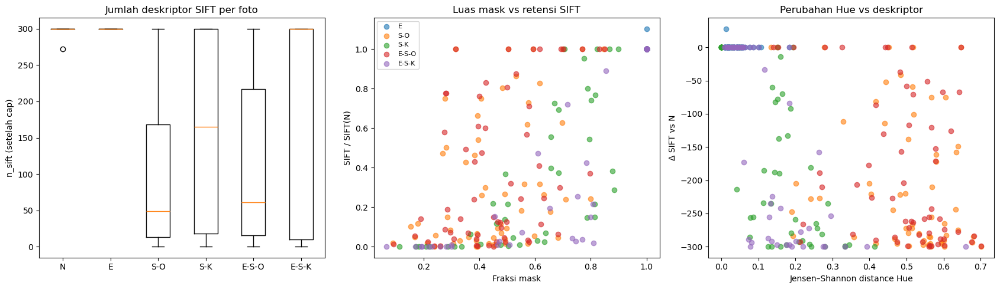

Plot: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\02_feature_loss.png
Korelasi Spearman luas mask vs retensi SIFT (deskriptif):
S-O rho= 0.378
S-K rho= 0.923
E-S-O rho= 0.411
E-S-K rho= 0.979


In [16]:
feature_rows=[]
ea_color_vectors={}  # Simpan hanya vektor kecil agar SIFT tidak diekstraksi ulang untuk histogram.
for ci in EA_CONDS:
    for i in range(len(meta)):
        d=raw_features(i,ci,EA_FIXED_PID)
        ea_color_vectors[(i,ci)]=d['color'].copy()
        frac=float(processed(i,ci)[1].mean())
        row=dict(image=str(meta.iloc[i].image),label=str(y[i]),condition=ci,
                 mask_fraction=frac,n_sift=int(len(d['desc'])),
                 sobel_mean=float(d['sobel'][0]),canny_density=float(d['canny'][0]))
        row['color_vector_norm']=float(np.linalg.norm(np.nan_to_num(d['color'])))
        feature_rows.append(row)
ea_feature=pd.DataFrame(feature_rows)

ea_original_feature_qc=analysis_read_csv('feature_qc_profile0.csv').rename(columns={'input':'condition','n_sift':'n_sift_run'})
ea_feature=ea_feature.merge(ea_original_feature_qc[['image','condition','n_sift_run']],on=['image','condition'],validate='one_to_one')
if not ea_feature.n_sift.eq(ea_feature.n_sift_run).all():
    raise RuntimeError('Jumlah SIFT hasil diagnosis berbeda dari QC sumber run. Periksa versi OpenCV dan konfigurasi sebelum menafsirkan hasil.')
print('Jumlah SIFT profil 0 cocok dengan seluruh 360 baris QC sumber run.')

ea_feat_base=ea_feature.query("condition == 'N'")[['image','n_sift']].rename(columns={'n_sift':'n_sift_N'})
ea_feature=ea_feature.merge(ea_feat_base,on='image',validate='many_to_one')
ea_feature['sift_retention_ratio']=np.divide(ea_feature.n_sift,ea_feature.n_sift_N,
    out=np.full(len(ea_feature),np.nan),where=ea_feature.n_sift_N.to_numpy()!=0)
ea_feature['sift_delta']=ea_feature.n_sift-ea_feature.n_sift_N

p=PROFILES[EA_FIXED_PID]; boundaries=np.cumsum([0,*p['bins']])
# Distribusi referensi ditentukan sebelum kondisi dibandingkan; tidak dilatih pada label/test.
ea_hsv_reference={str(meta.iloc[i].image):ea_color_vectors[(i,'N')] for i in range(len(meta))}
ea_js=[]
for r in ea_feature.itertuples():
    c0=ea_hsv_reference[r.image]
    c1=ea_color_vectors[(EA_IDX[r.image],r.condition)]
    dist=[]
    for j in range(3):
        a=c0[boundaries[j]:boundaries[j+1]]
        b=c1[boundaries[j]:boundaries[j+1]]
        dist.append(float(jensenshannon(a,b,base=2)) if np.isfinite(a).all() and np.isfinite(b).all() else np.nan)
    ea_js.append(dist)
ea_feature[['hue_js','saturation_js','value_js']]=np.asarray(ea_js)
ea_feature=ea_feature.merge(ea_transition[['image','condition','transition']],
    on=['image','condition'],how='left',validate='one_to_one')
ea_csv(ea_feature,'02_feature_loss_per_image.csv')
ea_feature_summary=ea_csv(ea_feature.groupby(['condition','label'],as_index=False).agg(
    n_images=('image','size'),sift_mean=('n_sift','mean'),sift_median=('n_sift','median'),
    no_sift=('n_sift',lambda s:int((s==0).sum())),
    retention_mean=('sift_retention_ratio','mean'),mask_mean=('mask_fraction','mean'),
    hue_js_mean=('hue_js','mean'),canny_density_mean=('canny_density','mean')),
    '02_feature_loss_by_class.csv')
display(ea_feature.groupby('condition')[['n_sift','sift_retention_ratio','mask_fraction','hue_js','canny_density']].mean().round(3))

fig,axs=plt.subplots(1,3,figsize=(17,5))
axs[0].boxplot([ea_feature.loc[ea_feature.condition.eq(c),'n_sift'] for c in EA_CONDS],tick_labels=EA_CONDS)
axs[0].set(title='Jumlah deskriptor SIFT per foto',ylabel='n_sift (setelah cap)')
for ci in EA_CONDS[1:]:
    d=ea_feature[ea_feature.condition.eq(ci)]
    axs[1].scatter(d.mask_fraction,d.sift_retention_ratio,label=ci,alpha=.6)
axs[1].set(title='Luas mask vs retensi SIFT',xlabel='Fraksi mask',ylabel='SIFT / SIFT(N)')
axs[1].legend(fontsize=8)
for ci in EA_CONDS[1:]:
    d=ea_feature[ea_feature.condition.eq(ci)]
    axs[2].scatter(d.hue_js,d.sift_delta,label=ci,alpha=.6)
axs[2].set(title='Perubahan Hue vs deskriptor',xlabel='Jensen–Shannon distance Hue',ylabel='Δ SIFT vs N')
fig.tight_layout();ea_savefig(fig,'02_feature_loss.png')
print('Korelasi Spearman luas mask vs retensi SIFT (deskriptif):')
for ci in EA_CONDS[2:]:
    d=ea_feature[ea_feature.condition.eq(ci)].dropna(subset=['sift_retention_ratio'])
    print(ci, 'rho=',round(float(spearmanr(d.mask_fraction,d.sift_retention_ratio).statistic),3))

### 11b. Panel visual: mask dan lokasi keypoint SIFT

Visualisasi keypoint meniru aturan deteksi dan filter jarak mask pada `extract_rgb_features`. Untuk keterbacaan hanya **maksimum 70 titik** ditampilkan; total deskriptor tetap berasal dari fungsi asli. Pilih kasus yang berubah dari benar menjadi salah.

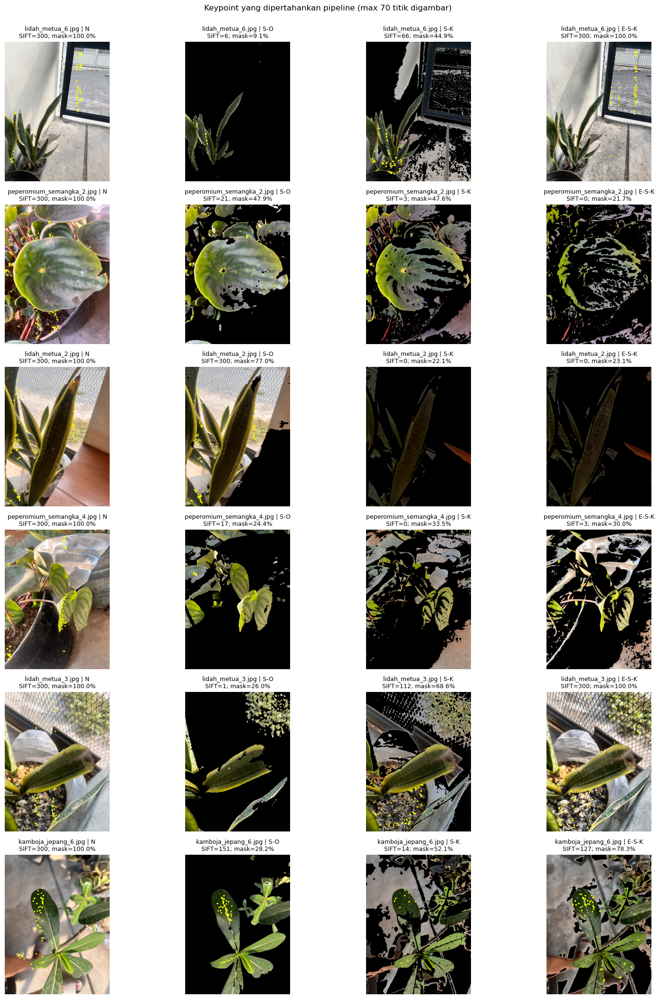

Plot: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\02_sift_keypoints_cases.png


In [17]:
@lru_cache(maxsize=512)
def ea_visible_kps(i,condition):
    rgb,mask,_=processed(i,condition)
    gray=cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
    sift=cv2.SIFT_create(nfeatures=300 if SMOKE_TEST else 1200)
    kp,_=sift.detectAndCompute(gray,mask.astype(np.uint8)*255)
    distance=cv2.distanceTransform(np.pad(mask.astype(np.uint8),1),cv2.DIST_L2,5)[1:-1,1:-1]
    kept=[k for k in kp if distance[min(round(k.pt[1]),gray.shape[0]-1),
        min(round(k.pt[0]),gray.shape[1]-1)] > np.ceil(6*k.size)]
    return kept

cases=ea_transition.query("transition == 'benar_ke_salah'").sort_values(['mask_fraction','image'])
examples=list(dict.fromkeys(cases.image))[:EA_MAX_EXAMPLES]
if not examples: examples=list(meta.image.head(EA_MAX_EXAMPLES))
show_conds=['N','S-O','S-K','E-S-K']
fig,axs=plt.subplots(len(examples),len(show_conds),figsize=(4.1*len(show_conds),3.5*len(examples)),squeeze=False)
for rr,name in enumerate(examples):
    i=EA_IDX[name]
    for cc,ci in enumerate(show_conds):
        rgb,mask,_=processed(i,ci)
        scene=np.where(mask[...,None],rgb,0) if ci!='N' else rgb
        axs[rr,cc].imshow(scene)
        for kp in ea_visible_kps(i,ci)[:70]:
            axs[rr,cc].add_patch(plt.Circle(kp.pt,2,color='yellow',alpha=.8))
        n=int(ea_feature.loc[ea_feature.image.eq(name)&ea_feature.condition.eq(ci),'n_sift'].iloc[0])
        axs[rr,cc].set_title(f'{name} | {ci}\nSIFT={n}; mask={mask.mean():.1%}',fontsize=9)
        axs[rr,cc].axis('off')
fig.suptitle('Keypoint yang dipertahankan pipeline (max 70 titik digambar)',y=1.0)
fig.tight_layout();ea_savefig(fig,'02_sift_keypoints_cases.png')

## 12. Segmentation/mask quality — tidak menganggap luas mask = IoU

Hitung luas, sentuhan tepi, dan fragmentasi komponen mask per kelas untuk menemukan *failure mode* algoritme. **Mask hampir penuh/kecil bukan bukti otomatis salah**. Jika tersedia anotasi daun biner di `Dataset/leaf_masks`, baru hitung Dice, IoU, foreground recall, dan background leakage. Jika tidak tersedia, metrik validasi segmentasi dilewati dengan peringatan, **tidak** dibuat-buat.

Mask ground truth tersedia: 0 / 60
CSV: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\03_segmentation_mask_quality.csv
CSV: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\03_mask_quality_by_class.csv


,condition,label,n_images,mask_mean,mean_components,near_full,very_small,iou_mean,dice_mean
0,E-S-K,Aglaonema,10,1.000,1.000,10,0,NaN,NaN
1,E-S-K,Daun nangka,9,0.962,8.333,7,0,NaN,NaN
2,E-S-K,Kamboja jepang,9,0.501,55.889,0,1,NaN,NaN
3,E-S-K,Lidah metua,12,0.787,42.750,7,0,NaN,NaN
4,E-S-K,Paku tanduk rusa,14,0.919,59.857,9,0,NaN,NaN
5,E-S-K,Peperomium semangka,6,0.205,252.500,0,3,NaN,NaN
6,E-S-O,Aglaonema,10,0.483,31.400,0,0,NaN,NaN
7,E-S-O,Daun nangka,9,0.581,51.556,0,0,NaN,NaN
8,E-S-O,Kamboja jepang,9,0.360,31.111,0,1,NaN,NaN
9,E-S-O,Lidah metua,12,0.393,34.000,0,2,NaN,NaN


PERINGATAN: tidak ada anotasi ground truth. Kolom IoU/Dice/Recall/Leakage = NaN; jangan klaim akurasi segmentasi.


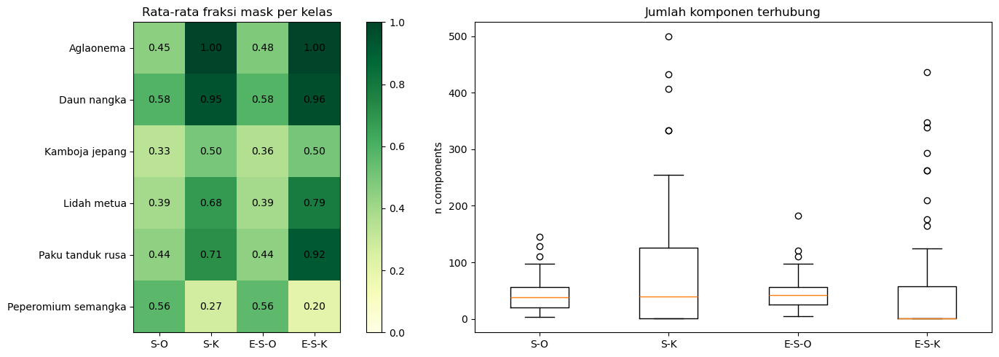

Plot: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\03_mask_diagnostics.png


In [18]:
def ea_manual_mask(i):
    stem=Path(str(meta.iloc[i].image)).stem
    label=str(meta.iloc[i].label)
    candidates=[EA_GT_MASK_DIR/(stem+ext) for ext in ('.png','.jpg','.jpeg')]
    candidates += [EA_GT_MASK_DIR/label/(stem+ext) for ext in ('.png','.jpg','.jpeg')]
    match=next((p for p in candidates if p.is_file()),None)
    if match is None: return None
    with Image.open(match) as im:
        raw=np.asarray(ImageOps.exif_transpose(im).convert('L'))
    expected=load_rgb(i).shape[:2]
    if raw.shape!=expected:
        raw=cv2.resize(raw,(expected[1],expected[0]),interpolation=cv2.INTER_NEAREST)
    return raw>127

ea_has_manual=[ea_manual_mask(i) is not None for i in range(len(meta))]
print('Mask ground truth tersedia:',sum(ea_has_manual),'/',len(meta))
mask_rows=[]
for ci in EA_CONDS[2:]:
    for i in range(len(meta)):
        _,mask,_=processed(i,ci)
        h,w=mask.shape
        ncomps,labels_comp,stats,_=cv2.connectedComponentsWithStats(mask.astype(np.uint8),8)
        areas=stats[1:,cv2.CC_STAT_AREA] if ncomps>1 else np.asarray([],dtype=int)
        msum=int(mask.sum())
        borders=np.r_[mask[0,:],mask[-1,:],mask[1:-1,0],mask[1:-1,-1]]
        record=dict(image=str(meta.iloc[i].image),label=str(y[i]),condition=ci,
            mask_fraction=float(mask.mean()),n_components=int(len(areas)),
            largest_component_fraction=float(areas.max()/msum) if msum else 0.,
            border_occupancy=float(borders.mean()),ground_truth_available=bool(ea_has_manual[i]),
            iou=np.nan,dice=np.nan,foreground_recall=np.nan,background_leakage=np.nan)
        gt=ea_manual_mask(i)
        if gt is not None:
            tp=np.logical_and(mask,gt).sum();fp=np.logical_and(mask,~gt).sum()
            fn=np.logical_and(~mask,gt).sum();tn=np.logical_and(~mask,~gt).sum()
            record.update(iou=float(tp/(tp+fp+fn)) if tp+fp+fn else np.nan,
                dice=float(2*tp/(2*tp+fp+fn)) if 2*tp+fp+fn else np.nan,
                foreground_recall=float(tp/(tp+fn)) if tp+fn else np.nan,
                background_leakage=float(fp/(fp+tn)) if fp+tn else np.nan)
        mask_rows.append(record)
ea_masks=ea_csv(pd.DataFrame(mask_rows),'03_segmentation_mask_quality.csv')
mask_summary=ea_csv(ea_masks.groupby(['condition','label'],as_index=False).agg(
    n_images=('image','size'),mask_mean=('mask_fraction','mean'),
    mean_components=('n_components','mean'),
    near_full=('mask_fraction',lambda x:int((x>.98).sum())),
    very_small=('mask_fraction',lambda x:int((x<.2).sum())),
    iou_mean=('iou','mean'),dice_mean=('dice','mean')),
    '03_mask_quality_by_class.csv')
display(mask_summary.round(3))
if not any(ea_has_manual):
    print('PERINGATAN: tidak ada anotasi ground truth. Kolom IoU/Dice/Recall/Leakage = NaN; jangan klaim akurasi segmentasi.')
elif not all(ea_has_manual):
    print('PERINGATAN: IoU/Dice hanya berlaku pada',sum(ea_has_manual),'citra beranotasi; sampelnya tidak otomatis representatif.')

view=mask_summary.pivot(index='label',columns='condition',values='mask_mean').reindex(index=LABELS,columns=EA_CONDS[2:])
fig,axs=plt.subplots(1,2,figsize=(15,5))
img=axs[0].imshow(view,cmap='YlGn',vmin=0,vmax=1)
axs[0].set_xticks(range(len(view.columns)),view.columns);axs[0].set_yticks(range(len(view)),view.index)
for (rr,cc),val in np.ndenumerate(view.to_numpy()):axs[0].text(cc,rr,f'{val:.2f}',ha='center',va='center')
axs[0].set_title('Rata-rata fraksi mask per kelas');fig.colorbar(img,ax=axs[0])
byci=[ea_masks.loc[ea_masks.condition.eq(c),'n_components'] for c in EA_CONDS[2:]]
axs[1].boxplot(byci,tick_labels=EA_CONDS[2:]);axs[1].set(title='Jumlah komponen terhubung',ylabel='n components')
fig.tight_layout();ea_savefig(fig,'03_mask_diagnostics.png')

## 13. Feature overlap / class separability — **shared visual vocabulary** (train only)

**Kunci interpretasi:** Word ke-1 pada BoVW yang dilatih secara terpisah untuk `N` dan `S-O` bisa berbeda arti. Agar perbandingan antarkondisi bermakna, untuk **setiap outer fold** kita memakai *codebook* dari `N`-train pada fold itu untuk semua kondisi. Imputer dan StandardScaler juga hanya fit pada `N`-train dan dipakai identik ke semua kondisi di fold tersebut. Foto evaluasi tidak dipakai fit codebook, scaler, PCA, atau model.

Indikator per fold: **silhouette** dan **Fisher ratio** pada train; pada foto outer-test hitung **nearest-neighbor same-class ratio** dan **margin nearest-same vs nearest-other** relatif terhadap train. Sifatnya diagnosis fitur, bukan metrik validasi model yang sudah dituning. Semua *distance* memakai representasi F4 yang diimputasi dan distandardisasi di ruang yang sama.

**Default dilewati.** Snapshot GitHub tidak menyimpan objek kamus/model. Jika `RUN_NEW_DIAGNOSTIC_MODELS=True`, bagian ini melakukan fit baru untuk diagnosis pada split GitHub yang sama. Hasilnya disimpan terpisah dan tidak disebut sebagai model asli.


In [19]:
if RUN_NEW_DIAGNOSTIC_MODELS:
    @lru_cache(maxsize=64)
    def ea_shared_matrix(fold,ci):
        tr,_=outer[fold]
        pid=EA_FOLD_PID[fold]
        train_tuple=tuple(map(int,tr))
        if ('N',pid,train_tuple) not in _bovw_models:
            encode('N',pid,train_tuple)  # fit hanya N-train fold ini
        km=_bovw_models[('N',pid,train_tuple)]
        words=int(PROFILES[pid]['words'])
        rows=[]
        for i in range(len(meta)):
            d=raw_features(i,ci,pid)
            h=np.bincount(km.predict(d['desc']),minlength=words).astype(float) if len(d['desc']) else np.zeros(words)
            h/=max(h.sum(),1.)
            rows.append(np.r_[d['color'],h])
        return np.vstack(rows)

    @lru_cache(maxsize=32)
    def ea_common_projection(fold):
        tr,_=outer[fold]
        Xn=ea_shared_matrix(fold,'N')
        imputer=SimpleImputer(strategy='median',keep_empty_features=True).fit(Xn[tr])
        scaler=StandardScaler().fit(imputer.transform(Xn[tr]))
        return imputer,scaler

    def ea_common_features(fold,condition):
        imp,sca=ea_common_projection(fold)
        return sca.transform(imp.transform(ea_shared_matrix(fold,condition)))

    def ea_fisher_by_class(X,labels):
        # trace(S_between) / trace(S_within), dengan within total dan between berbobot n kelas
        classes=np.unique(labels)
        grand=X.mean(axis=0)
        between=0.; within=0.
        for c in classes:
            z=X[labels==c]
            mu=z.mean(axis=0)
            between += len(z)*float(np.sum((mu-grand)**2))
            within += float(np.sum((z-mu)**2))
        return between/max(within,1e-12)

    ea_sep_rows=[];ea_neighbor_rows=[];ea_pair_rows=[]
    for fold,(tr,te) in enumerate(outer):
        print(f'Feature overlap: outer fold {fold+1}/{len(outer)}',flush=True)
        for ci in EA_CONDS:
            Z=ea_common_features(fold,ci)
            train_Z=Z[tr];train_y=y[tr]
            sil=silhouette_score(train_Z,train_y) if len(set(train_y))>=2 and len(train_y)>len(set(train_y)) else np.nan
            fisher=ea_fisher_by_class(train_Z,train_y)
            ea_sep_rows.append(dict(fold=fold,condition=ci,profile=EA_FOLD_PID[fold],
                                    silhouette_train=sil,fisher_train=fisher))
            # Per pasangan kelas: Fisher jarak centroid / jumlah variasi dalam kedua kelas.
            from itertools import combinations
            for a,b in combinations(LABELS,2):
                A=train_Z[train_y==a];B=train_Z[train_y==b]
                ma=A.mean(axis=0);mb=B.mean(axis=0)
                var=float(np.mean(np.sum((A-ma)**2,axis=1))+np.mean(np.sum((B-mb)**2,axis=1)))
                ea_pair_rows.append(dict(fold=fold,condition=ci,class_a=a,class_b=b,
                    fisher_pair=float(np.sum((ma-mb)**2))/max(var,1e-12)))
            distances=cdist(Z[te],train_Z,metric='euclidean')
            k=min(5,len(tr))
            for j,i in enumerate(te):
                ds=distances[j]
                same=ds[train_y==y[i]]
                other=ds[train_y!=y[i]]
                nearest_same=float(same.min()) if len(same) else np.nan
                nearest_other=float(other.min()) if len(other) else np.nan
                margin=(nearest_other-nearest_same)/max(nearest_other+nearest_same,1e-12)
                knn=sorted(np.argsort(ds)[:k])
                same_ratio=float(np.mean(train_y[knn]==y[i]))
                ea_neighbor_rows.append(dict(fold=fold,condition=ci,image=str(meta.iloc[i].image),
                    label=str(y[i]),same_class_knn_ratio=same_ratio,neighbor_margin=margin,
                    nearest_same_distance=nearest_same,nearest_other_distance=nearest_other))

    ea_sep=ea_csv(pd.DataFrame(ea_sep_rows),'04_separability_by_fold.csv')
    ea_neighbors=ea_csv(pd.DataFrame(ea_neighbor_rows),'04_neighbors_oof.csv')
    ea_pairs=ea_csv(pd.DataFrame(ea_pair_rows),'04_pairwise_fisher_by_fold.csv')
    print('Rata-rata antar fold (train):'); display(ea_sep.groupby('condition')[['silhouette_train','fisher_train']].agg(['mean','std']).round(3))
    print('Rata-rata held-out NN:');display(ea_neighbors.groupby('condition')[['same_class_knn_ratio','neighbor_margin']].mean().round(3))

    base_marg=ea_neighbors[ea_neighbors.condition.eq('N')][['image','neighbor_margin']].rename(columns={'neighbor_margin':'margin_N'})
    ea_neighbors=ea_neighbors.merge(base_marg,on='image',validate='many_to_one')
    ea_neighbors['margin_delta_vs_N']=ea_neighbors.neighbor_margin-ea_neighbors.margin_N
    ea_neighbors=ea_neighbors.merge(ea_transition[['image','condition','transition']],on=['image','condition'],validate='one_to_one')
    ea_csv(ea_neighbors,'04_neighbors_with_delta.csv')
    print('10 perubahan margin paling negatif pada segmentasi:')
    display(ea_neighbors[ea_neighbors.condition.isin(EA_CONDS[2:])].nsmallest(10,'margin_delta_vs_N')
            [['condition','image','label','neighbor_margin','margin_N','margin_delta_vs_N','transition']])
else:
    print('Dilewati: kamus/model asli tidak tersimpan di GitHub. Aktifkan RUN_NEW_DIAGNOSTIC_MODELS hanya untuk eksperimen diagnostik baru.')


Feature overlap: outer fold 1/5
Feature overlap: outer fold 2/5
Feature overlap: outer fold 3/5
Feature overlap: outer fold 4/5
Feature overlap: outer fold 5/5
CSV: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\04_separability_by_fold.csv
CSV: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\04_neighbors_oof.csv
CSV: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\04_pairwise_fisher_by_fold.csv
Rata-rata antar fold (train):


silhouette_train        fisher_train       
                      mean    std         mean    std
condition                                            
E                    0.083  0.010        0.492  0.019
E-S-K               -0.072  0.015        0.334  0.010
E-S-O               -0.078  0.037        0.205  0.056
N                    0.098  0.009        0.535  0.030
S-K                 -0.092  0.021        0.259  0.034
S-O                 -0.050  0.019        0.264  0.044

Rata-rata held-out NN:


,same_class_knn_ratio,neighbor_margin
condition,,
E,0.653,0.077
E-S-K,0.540,0.096
E-S-O,0.510,0.083
N,0.707,0.086
S-K,0.523,0.073
S-O,0.467,0.067


CSV: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\04_neighbors_with_delta.csv
10 perubahan margin paling negatif pada segmentasi:


,condition,image,label,neighbor_margin,margin_N,margin_delta_vs_N,transition
178,S-O,paku_tanduk_rusa_6.jpeg,Paku tanduk rusa,-0.543852,0.064604,-0.608456,tetap_benar
246,S-O,lidah_metua_3.jpg,Lidah metua,-0.415572,0.015527,-0.431099,benar_ke_salah
247,S-O,lidah_metua_6.jpg,Lidah metua,-0.268571,0.044178,-0.312749,benar_ke_salah
208,E-S-K,kamboja_jepang_6.jpg,Kamboja jepang,-0.192470,0.078894,-0.271365,tetap_benar
71,E-S-K,peperomium_semangka_5.jpg,Peperomium semangka,-0.012362,0.231939,-0.244300,tetap_benar
32,S-O,paku_tanduk_rusa_10.jpeg,Paku tanduk rusa,-0.077093,0.165342,-0.242435,benar_ke_salah
59,E-S-O,peperomium_semangka_5.jpg,Peperomium semangka,-0.009715,0.231939,-0.241654,tetap_benar
119,S-K,peperomium_semangka_3.jpg,Peperomium semangka,-0.193055,0.048450,-0.241504,tetap_salah
202,E-S-O,paku_tanduk_rusa_6.jpeg,Paku tanduk rusa,-0.172445,0.064604,-0.237049,benar_ke_salah
35,S-O,peperomium_semangka_5.jpg,Peperomium semangka,-0.004007,0.231939,-0.235946,tetap_benar


### 13b. Plot PCA (fit **N-train**, tampilan outer-test saja) dan heatmap Fisher antarkelas

Semua kondisi pada plot PCA **menggunakan satu basis koordinat yang sama pada satu fold**; jangan gabungkan koordinat PCA dari fold yang berbeda. Warna melambangkan label kelas asli. Lingkaran abu-abu menunjukkan titik N-train sebagai referensi posisi. PCA tidak dipakai dalam training SVM. Besarnya overlap pada PCA 2D **belum tentu identik** dengan overlap di dimensi penuh, karena informasi hilang saat proyeksi.

**Default dilewati.** Snapshot GitHub tidak menyimpan objek kamus/model. Jika `RUN_NEW_DIAGNOSTIC_MODELS=True`, bagian ini melakukan fit baru untuk diagnosis pada split GitHub yang sama. Hasilnya disimpan terpisah dan tidak disebut sebagai model asli.


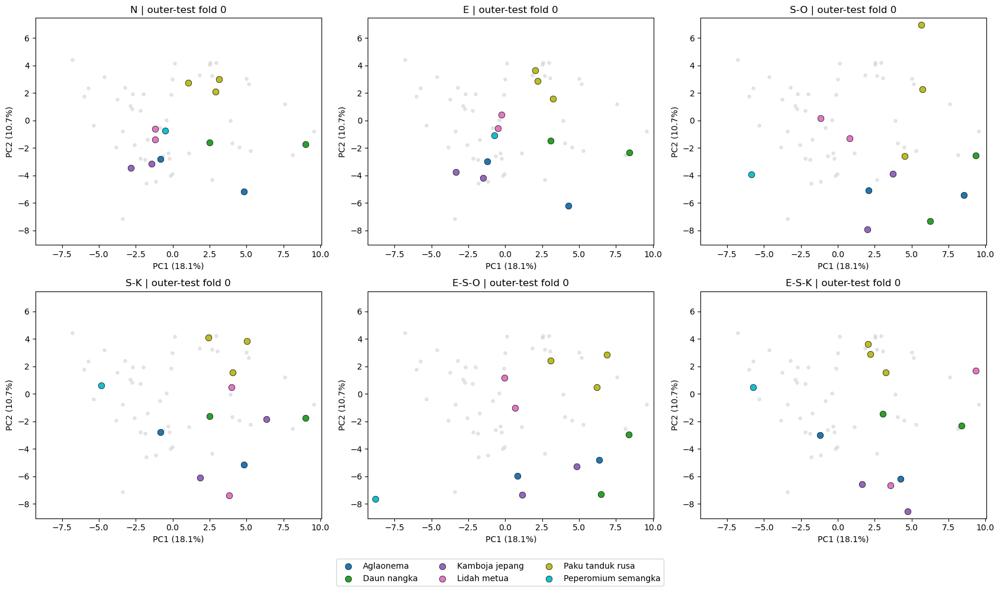

Plot: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\04_shared_feature_pca.png


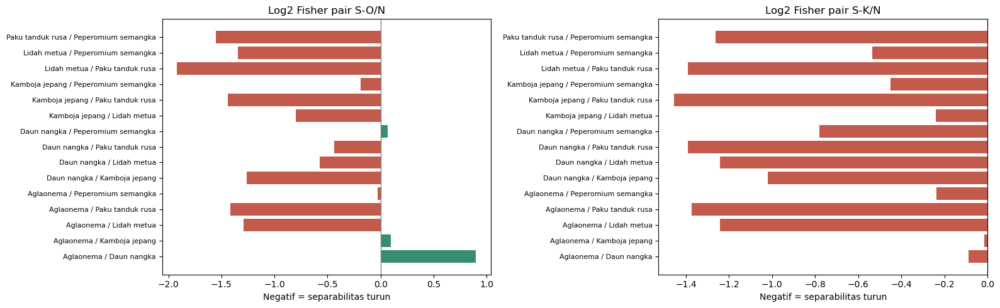

Plot: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\04_fisher_pairwise_change.png


In [20]:
if RUN_NEW_DIAGNOSTIC_MODELS:
    fold=EA_PLOT_FOLD;tr,te=outer[fold]
    Z_n=ea_common_features(fold,'N')
    pca=PCA(n_components=2,random_state=SEED).fit(Z_n[tr])
    projected={ci:pca.transform(ea_common_features(fold,ci)[te]) for ci in EA_CONDS}
    train_positions=pca.transform(Z_n[tr]);combined=np.vstack([train_positions,*projected.values()])
    xlim=(combined[:,0].min()-.5,combined[:,0].max()+.5)
    ylim=(combined[:,1].min()-.5,combined[:,1].max()+.5)
    fig,axs=plt.subplots(2,3,figsize=(17,10),squeeze=False)
    colors=plt.get_cmap('tab10',len(LABELS))
    for ax,ci in zip(axs.flat,EA_CONDS):
        ax.scatter(train_positions[:,0],train_positions[:,1],s=14,c='lightgray',alpha=.55,label='N train')
        pts=projected[ci]
        for k,label in enumerate(LABELS):
            sel=y[te]==label
            ax.scatter(pts[sel,0],pts[sel,1],s=58,color=colors(k),edgecolors='black',linewidths=.5,label=label)
        ax.set(xlim=xlim,ylim=ylim,title=f'{ci} | outer-test fold {fold}',
               xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})',
               ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
    handles,labels=axs.flat[0].get_legend_handles_labels()
    fig.legend(handles[1:],labels[1:],loc='lower center',ncol=3,fontsize=10)
    fig.tight_layout(rect=(0,.06,1,1));ea_savefig(fig,'04_shared_feature_pca.png')

    pairwide=(ea_pairs.pivot_table(index=['class_a','class_b'],columns='condition',values='fisher_pair',aggfunc='mean'))
    pairs=[(a,b) for a in LABELS for b in LABELS if a<b]
    fig,axs=plt.subplots(1,2,figsize=(16,max(5,.31*len(pairs))))
    for ax,ci in zip(axs,['S-O','S-K']):
        values=np.array([np.log2((pairwide.loc[(a,b),ci]+1e-9)/(pairwide.loc[(a,b),'N']+1e-9)) for a,b in pairs])
        ax.barh(range(len(pairs)),values,color=np.where(values<0,'#C35B4D','#368D71'))
        ax.set_yticks(range(len(pairs)),[f'{a} / {b}' for a,b in pairs],fontsize=8)
        ax.axvline(0,color='gray',lw=1)
        ax.set(title=f'Log2 Fisher pair {ci}/N',xlabel='Negatif = separabilitas turun')
    fig.tight_layout();ea_savefig(fig,'04_fisher_pairwise_change.png')
else:
    print('Dilewati: kamus/model asli tidak tersimpan di GitHub. Aktifkan RUN_NEW_DIAGNOSTIC_MODELS hanya untuk eksperimen diagnostik baru.')


## 14. Background dependency — klasifikasi region foreground vs background

Diagnosis ini memisahkan daerah gambar: `full`, `foreground-only`, `background-only`. **Jika belum ada mask manual lengkap untuk seluruh foto**, region ditentukan oleh K-Means otomatis (`EA_MASK_AUTO='S-K'`), sehingga foreground/background hanya **proxy** dan bisa salah; hasil tidak boleh disebut bukti definitif *background shortcut*. Jika 60/60 ground truth tersedia, secara otomatis digunakan sebagai sumber region.

Untuk tiap fold: kamus BoVW dipelajari dari `N`-train, sedangkan SVM (`C=1`, gamma numerik tetap) dilatih ulang pada tiap jenis region **menggunakan foto asli train tanpa augmentasi**, dievaluasi pada foto asli outer-test yang sama. Ini studi diagnostik terkontrol terpisah dari skor benchmark augmentasi.

**Default dilewati.** Snapshot GitHub tidak menyimpan objek kamus/model. Jika `RUN_NEW_DIAGNOSTIC_MODELS=True`, bagian ini melakukan fit baru untuk diagnosis pada split GitHub yang sama. Hasilnya disimpan terpisah dan tidak disebut sebagai model asli.


Mode pembatas region: auto_proxy
Metode segmentasi: S-K
Background analysis: fold 1/5
Background analysis: fold 2/5
Background analysis: fold 3/5
Background analysis: fold 4/5
Background analysis: fold 5/5
CSV: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\05_background_dependency_S-K_oof.csv
CSV: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\05_background_dependency_S-K_summary.csv


,region,mask_source,mask_method,accuracy,macro_f1
0,background,auto_proxy,S-K,0.483333,0.427519
1,foreground,auto_proxy,S-K,0.783333,0.762895
2,full,auto_proxy,S-K,0.916667,0.895886


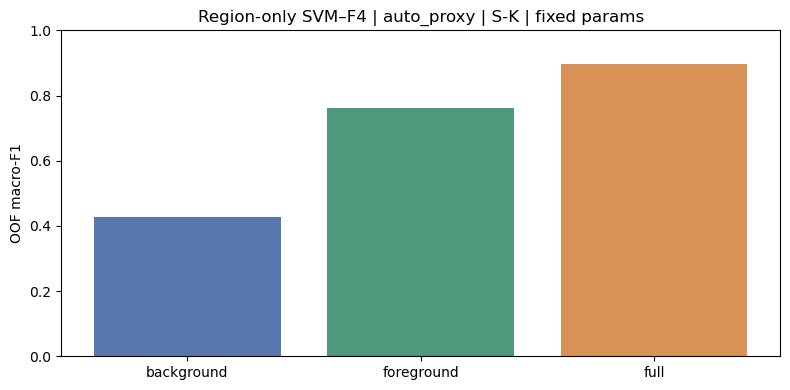

Plot: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\05_background_dependency_S-K.png
PERINGATAN: foreground/background dibentuk dari mask otomatis; hasil background-only adalah proxy, bukan verifikasi shortcut learning.


In [29]:
if RUN_NEW_DIAGNOSTIC_MODELS:
    EA_BG_MASK_MODE = 'manual' if all(ea_has_manual) else 'auto_proxy'
    EA_MASK_AUTO = 'S-K'

    suffix = EA_MASK_AUTO if EA_BG_MASK_MODE == 'auto_proxy' else 'manual'

    print('Mode pembatas region:', EA_BG_MASK_MODE)
    print('Metode segmentasi:', suffix)

    @lru_cache(maxsize=400)
    def ea_region_block(i, region, pid):
        rgb = load_rgb(i)

        if region == 'full':
            return raw_features(i, 'N', pid)

        selected = (
            ea_manual_mask(i)
            if EA_BG_MASK_MODE == 'manual'
            else processed(i, EA_MASK_AUTO)[1]
        )

        if region == 'background':
            selected = ~selected

        if region not in ('foreground', 'background'):
            raise ValueError(region)

        return extract_rgb_features(rgb, selected, pid, int(i))

    def ea_region_matrix(fold, region):
        tr, _ = outer[fold]
        pid = EA_FOLD_PID[fold]

        key = ('N', pid, tuple(map(int, tr)))

        if key not in _bovw_models:
            encode('N', pid, tuple(map(int, tr)))

        km = _bovw_models[key]
        v = int(PROFILES[pid]['words'])
        rows = []

        for i in range(len(meta)):
            d = ea_region_block(i, region, pid)

            h = (
                np.bincount(
                    km.predict(d['desc']),
                    minlength=v
                ).astype(float)
                if len(d['desc'])
                else np.zeros(v)
            )

            h /= max(1., h.sum())
            rows.append(np.r_[d['color'], h])

        return np.vstack(rows)

    ea_bg_rows = []

    for fold, (tr, te) in enumerate(outer):
        print(f'Background analysis: fold {fold + 1}/{len(outer)}')

        for region in ('full', 'foreground', 'background'):
            X = ea_region_matrix(fold, region)

            gamma = 1. / X.shape[1]

            mdl = estimator(
                'SVM',
                {'C': 1., 'gamma': gamma}
            ).fit(X[tr], y[tr])

            pred = mdl.predict(X[te])

            ea_bg_rows.extend(
                dict(
                    fold=fold,
                    region=region,
                    image=str(meta.iloc[i].image),
                    true=str(y[i]),
                    pred=str(p),
                    correct=bool(y[i] == p),
                    mask_source=EA_BG_MASK_MODE,
                    mask_method=suffix
                )
                for i, p in zip(te, pred)
            )

    # Simpan prediksi OOF
    ea_bg = ea_csv(
        pd.DataFrame(ea_bg_rows),
        f'05_background_dependency_{suffix}_oof.csv'
    )

    # Simpan ringkasan evaluasi
    ea_bg_summary = ea_csv(
        pd.DataFrame([
            dict(
                region=region,
                mask_source=EA_BG_MASK_MODE,
                mask_method=suffix,
                accuracy=accuracy_score(d.true, d.pred),
                macro_f1=f1_score(
                    d.true,
                    d.pred,
                    labels=LABELS,
                    average='macro',
                    zero_division=0
                )
            )
            for region, d in ea_bg.groupby('region')
        ]),
        f'05_background_dependency_{suffix}_summary.csv'
    )

    display(ea_bg_summary)

    # Visualisasi
    fig, ax = plt.subplots(figsize=(8, 4))

    ax.bar(
        ea_bg_summary.region,
        ea_bg_summary.macro_f1,
        color=['#5678AD', '#4F987B', '#DA9156']
    )

    ax.set(
        ylim=(0, 1),
        title=f'Region-only SVM–F4 | {EA_BG_MASK_MODE} | {suffix} | fixed params',
        ylabel='OOF macro-F1'
    )

    fig.tight_layout()

    ea_savefig(
        fig,
        f'05_background_dependency_{suffix}.png'
    )

    if EA_BG_MASK_MODE != 'manual':
        print(
            'PERINGATAN: foreground/background dibentuk dari '
            'mask otomatis; hasil background-only adalah proxy, '
            'bukan verifikasi shortcut learning.'
        )

else:
    print(
        'Dilewati: kamus/model asli tidak tersimpan di GitHub. '
        'Aktifkan RUN_NEW_DIAGNOSTIC_MODELS hanya untuk '
        'eksperimen diagnostik baru.'
    )

Mode pembatas region: auto_proxy
Metode segmentasi: S-O
Background analysis: fold 1/5
Background analysis: fold 2/5
Background analysis: fold 3/5
Background analysis: fold 4/5
Background analysis: fold 5/5
CSV: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\05_background_dependency_S-O_oof.csv
CSV: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\05_background_dependency_S-O_summary.csv


,region,mask_source,mask_method,accuracy,macro_f1
0,background,auto_proxy,S-O,0.633333,0.536153
1,foreground,auto_proxy,S-O,0.700000,0.637402
2,full,auto_proxy,S-O,0.916667,0.895886


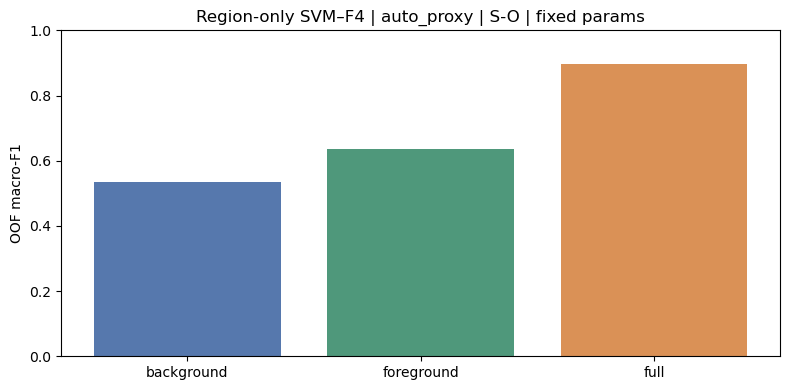

Plot: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\05_background_dependency_S-O.png
PERINGATAN: foreground/background dibentuk dari mask otomatis; hasil background-only adalah proxy, bukan verifikasi shortcut learning.


In [30]:
if RUN_NEW_DIAGNOSTIC_MODELS:
    EA_BG_MASK_MODE = 'manual' if all(ea_has_manual) else 'auto_proxy'
    EA_MASK_AUTO = 'S-O'

    suffix = EA_MASK_AUTO if EA_BG_MASK_MODE == 'auto_proxy' else 'manual'

    print('Mode pembatas region:', EA_BG_MASK_MODE)
    print('Metode segmentasi:', suffix)

    @lru_cache(maxsize=400)
    def ea_region_block(i, region, pid):
        rgb = load_rgb(i)

        if region == 'full':
            return raw_features(i, 'N', pid)

        selected = (
            ea_manual_mask(i)
            if EA_BG_MASK_MODE == 'manual'
            else processed(i, EA_MASK_AUTO)[1]
        )

        if region == 'background':
            selected = ~selected

        if region not in ('foreground', 'background'):
            raise ValueError(region)

        return extract_rgb_features(rgb, selected, pid, int(i))

    def ea_region_matrix(fold, region):
        tr, _ = outer[fold]
        pid = EA_FOLD_PID[fold]

        key = ('N', pid, tuple(map(int, tr)))

        if key not in _bovw_models:
            encode('N', pid, tuple(map(int, tr)))

        km = _bovw_models[key]
        v = int(PROFILES[pid]['words'])
        rows = []

        for i in range(len(meta)):
            d = ea_region_block(i, region, pid)

            h = (
                np.bincount(
                    km.predict(d['desc']),
                    minlength=v
                ).astype(float)
                if len(d['desc'])
                else np.zeros(v)
            )

            h /= max(1., h.sum())
            rows.append(np.r_[d['color'], h])

        return np.vstack(rows)

    ea_bg_rows = []

    for fold, (tr, te) in enumerate(outer):
        print(f'Background analysis: fold {fold + 1}/{len(outer)}')

        for region in ('full', 'foreground', 'background'):
            X = ea_region_matrix(fold, region)

            gamma = 1. / X.shape[1]

            mdl = estimator(
                'SVM',
                {'C': 1., 'gamma': gamma}
            ).fit(X[tr], y[tr])

            pred = mdl.predict(X[te])

            ea_bg_rows.extend(
                dict(
                    fold=fold,
                    region=region,
                    image=str(meta.iloc[i].image),
                    true=str(y[i]),
                    pred=str(p),
                    correct=bool(y[i] == p),
                    mask_source=EA_BG_MASK_MODE,
                    mask_method=suffix
                )
                for i, p in zip(te, pred)
            )

    # Simpan prediksi OOF
    ea_bg = ea_csv(
        pd.DataFrame(ea_bg_rows),
        f'05_background_dependency_{suffix}_oof.csv'
    )

    # Simpan ringkasan evaluasi
    ea_bg_summary = ea_csv(
        pd.DataFrame([
            dict(
                region=region,
                mask_source=EA_BG_MASK_MODE,
                mask_method=suffix,
                accuracy=accuracy_score(d.true, d.pred),
                macro_f1=f1_score(
                    d.true,
                    d.pred,
                    labels=LABELS,
                    average='macro',
                    zero_division=0
                )
            )
            for region, d in ea_bg.groupby('region')
        ]),
        f'05_background_dependency_{suffix}_summary.csv'
    )

    display(ea_bg_summary)

    # Visualisasi
    fig, ax = plt.subplots(figsize=(8, 4))

    ax.bar(
        ea_bg_summary.region,
        ea_bg_summary.macro_f1,
        color=['#5678AD', '#4F987B', '#DA9156']
    )

    ax.set(
        ylim=(0, 1),
        title=f'Region-only SVM–F4 | {EA_BG_MASK_MODE} | {suffix} | fixed params',
        ylabel='OOF macro-F1'
    )

    fig.tight_layout()

    ea_savefig(
        fig,
        f'05_background_dependency_{suffix}.png'
    )

    if EA_BG_MASK_MODE != 'manual':
        print(
            'PERINGATAN: foreground/background dibentuk dari '
            'mask otomatis; hasil background-only adalah proxy, '
            'bukan verifikasi shortcut learning.'
        )

else:
    print(
        'Dilewati: kamus/model asli tidak tersimpan di GitHub. '
        'Aktifkan RUN_NEW_DIAGNOSTIC_MODELS hanya untuk '
        'eksperimen diagnostik baru.'
    )

## 15. Controlled ablation — efek codebook, PCD, dan domain shift

Lakukan dua kontrol tanpa augmentasi, SVM `C=1`, `gamma=1/dim`, dan split outer yang sama:

- **Vocabulary control:** bandingkan BoVW yang dibuat per kondisi (seperti benchmark asli) melawan vocabulary **N-train yang sama** untuk setiap kondisi. Untuk masing-masing eksperimen, imputer/scaler fit pada *train kondisi itu* agar uji ini mengisolasi cara belajar vocabulary.
- **Train/test condition transfer:** gunakan **satu vocabulary N-train dan satu imputer/scaler N-train** untuk semua kondisi. Fit ulang SVM terpisah untuk setiap kondisi train, evaluasi pada semua kondisi test. Matriks diagonal = train/test pada kondisi sama; off-diagonal = *distribution shift*. Seluruh model di-fit tanpa menggunakan outer-test.

Kontrol ini **bukan** replikasi hasil nested CV + augmentasi di bagian sebelumnya: hyperparameter sengaja dibuat tetap supaya efek perlakuan lebih terisolasi.

**Default dilewati.** Snapshot GitHub tidak menyimpan objek kamus/model. Jika `RUN_NEW_DIAGNOSTIC_MODELS=True`, bagian ini melakukan fit baru untuk diagnosis pada split GitHub yang sama. Hasilnya disimpan terpisah dan tidak disebut sebagai model asli.


Controlled ablation: fold 1/5
Controlled ablation: fold 2/5
Controlled ablation: fold 3/5
Controlled ablation: fold 4/5
Controlled ablation: fold 5/5
CSV: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\06_shared_vs_separate_vocab_oof.csv
CSV: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\06_shared_vs_separate_vocab_summary.csv
CSV: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\06_cross_condition_transfer_oof.csv
CSV: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\06_cross_condition_transfer_summary.csv
Vocabulary control


,condition,vocab_mode,accuracy,macro_f1
0,E,separate_condition_vocab,0.867,0.828
1,E,shared_N_vocab,0.867,0.849
2,E-S-K,separate_condition_vocab,0.717,0.685
3,E-S-K,shared_N_vocab,0.750,0.716
4,E-S-O,separate_condition_vocab,0.733,0.664
5,E-S-O,shared_N_vocab,0.750,0.676
6,N,separate_condition_vocab,0.917,0.896
7,N,shared_N_vocab,0.917,0.896
8,S-K,separate_condition_vocab,0.767,0.748
9,S-K,shared_N_vocab,0.783,0.763


Transfer matrix


,train_condition,test_condition,accuracy,macro_f1
0,E,E,0.883,0.867
1,E,E-S-K,0.650,0.543
2,E,E-S-O,0.350,0.237
3,E,N,0.900,0.884
4,E,S-K,0.550,0.474
5,E,S-O,0.300,0.204
6,E-S-K,E,0.683,0.530
7,E-S-K,E-S-K,0.683,0.635
8,E-S-K,E-S-O,0.450,0.378
9,E-S-K,N,0.700,0.545


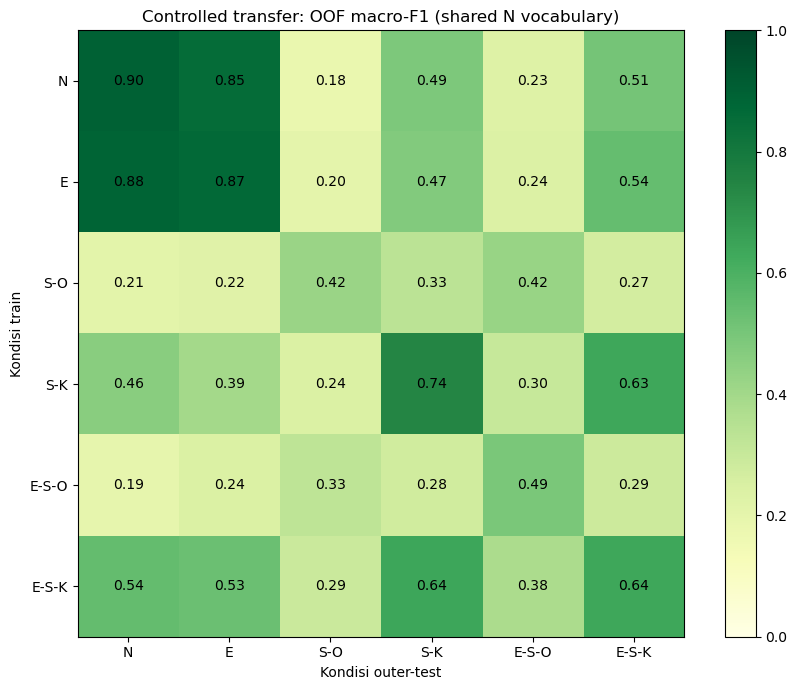

Plot: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\06_cross_condition_transfer.png


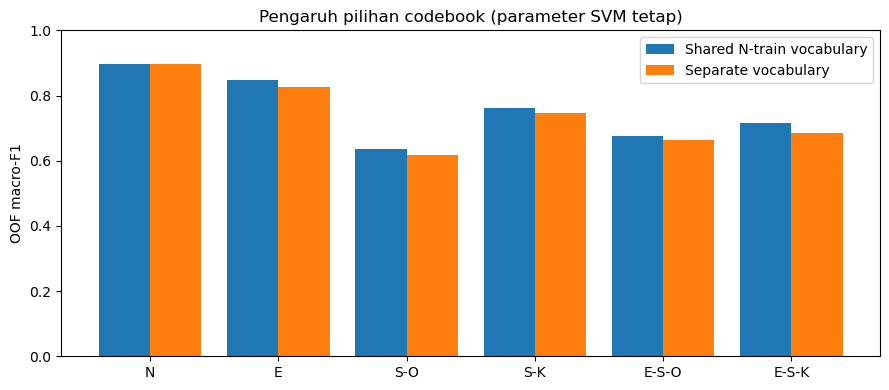

Plot: e:\PCD\Project Akhir\Notebook\reproduksi_github_f2473327_lengkap\error_analysis_tambahan\06_vocab_control.png


In [22]:
if RUN_NEW_DIAGNOSTIC_MODELS:
    ea_vocab_rows=[];ea_transfer_rows=[]
    for fold,(tr,te) in enumerate(outer):
        print(f'Controlled ablation: fold {fold+1}/{len(outer)}',flush=True)
        pid=EA_FOLD_PID[fold]
        n_dims=ea_shared_matrix(fold,'N').shape[1]
        param={'C':1.,'gamma':1./n_dims}
        # (A) Separate-vs-shared vocabulary; masing-masing kondisi fit scaler dari train sendiri.
        for ci in EA_CONDS:
            options={'shared_N_vocab':ea_shared_matrix(fold,ci),
                     'separate_condition_vocab':matrix(ci,pid,tr,'F4')}
            for vocab_name,X in options.items():
                est=estimator('SVM',param).fit(X[tr],y[tr])
                preds=est.predict(X[te])
                ea_vocab_rows.extend(dict(fold=fold,condition=ci,vocab_mode=vocab_name,
                    image=str(meta.iloc[i].image),true=str(y[i]),pred=str(p),correct=bool(y[i]==p))
                    for i,p in zip(te,preds))
        # (B) Transfer: imputer + scaler baseline N-train dipakai sama pada semua kondisi.
        projections={ci:ea_common_features(fold,ci) for ci in EA_CONDS}
        for train_cond in EA_CONDS:
            svc=SVC(kernel='rbf',**param).fit(projections[train_cond][tr],y[tr])
            for test_cond in EA_CONDS:
                pred=svc.predict(projections[test_cond][te])
                ea_transfer_rows.extend(dict(fold=fold,train_condition=train_cond,test_condition=test_cond,
                    image=str(meta.iloc[i].image),true=str(y[i]),pred=str(p),correct=bool(y[i]==p))
                    for i,p in zip(te,pred))
    ea_vocab=ea_csv(pd.DataFrame(ea_vocab_rows),'06_shared_vs_separate_vocab_oof.csv')
    ea_vocab_summary=ea_csv(pd.DataFrame([dict(condition=ci,vocab_mode=mode,
        accuracy=accuracy_score(d.true,d.pred),
        macro_f1=f1_score(d.true,d.pred,labels=LABELS,average='macro',zero_division=0))
        for (ci,mode),d in ea_vocab.groupby(['condition','vocab_mode'])]),'06_shared_vs_separate_vocab_summary.csv')
    ea_transfer=ea_csv(pd.DataFrame(ea_transfer_rows),'06_cross_condition_transfer_oof.csv')
    ea_transfer_summary=ea_csv(pd.DataFrame([dict(train_condition=train_c,test_condition=test_c,
        accuracy=accuracy_score(d.true,d.pred),
        macro_f1=f1_score(d.true,d.pred,labels=LABELS,average='macro',zero_division=0))
        for (train_c,test_c),d in ea_transfer.groupby(['train_condition','test_condition'])]),
        '06_cross_condition_transfer_summary.csv')
    print('Vocabulary control');display(ea_vocab_summary.round(3))
    print('Transfer matrix');display(ea_transfer_summary.round(3))

    mat=(ea_transfer_summary.pivot(index='train_condition',columns='test_condition',values='macro_f1')
         .reindex(index=EA_CONDS,columns=EA_CONDS))
    fig,ax=plt.subplots(figsize=(9,7))
    im=ax.imshow(mat,vmin=0,vmax=1,cmap='YlGn')
    ax.set_xticks(range(len(EA_CONDS)),EA_CONDS);ax.set_yticks(range(len(EA_CONDS)),EA_CONDS)
    ax.set(xlabel='Kondisi outer-test',ylabel='Kondisi train',title='Controlled transfer: OOF macro-F1 (shared N vocabulary)')
    for (rr,cc),v in np.ndenumerate(mat.to_numpy()):ax.text(cc,rr,f'{v:.2f}',ha='center',va='center')
    fig.colorbar(im,ax=ax);fig.tight_layout();ea_savefig(fig,'06_cross_condition_transfer.png')

    pivot=ea_vocab_summary.pivot(index='condition',columns='vocab_mode',values='macro_f1').reindex(EA_CONDS)
    fig,ax=plt.subplots(figsize=(9,4))
    xx=np.arange(len(pivot))
    ax.bar(xx-.2,pivot['shared_N_vocab'],width=.4,label='Shared N-train vocabulary')
    ax.bar(xx+.2,pivot['separate_condition_vocab'],width=.4,label='Separate vocabulary')
    ax.set_xticks(xx,pivot.index);ax.set(ylim=(0,1),ylabel='OOF macro-F1',title='Pengaruh pilihan codebook (parameter SVM tetap)')
    ax.legend();fig.tight_layout();ea_savefig(fig,'06_vocab_control.png')
else:
    print('Dilewati: kamus/model asli tidak tersimpan di GitHub. Aktifkan RUN_NEW_DIAGNOSTIC_MODELS hanya untuk eksperimen diagnostik baru.')
